# Is the best backtest real?

**Selection bias in strategy research: the deflated Sharpe ratio, the probability of backtest overfitting, and data-snooping tests**

Jett Jolliffe · October 2026

Strategy research is a search. A researcher tries lookback windows, entry thresholds, universes, rebalancing frequencies and cost assumptions, then reports the configuration that worked best. Each backtest on its own may be computed correctly, yet the reported result is still biased upwards, because it is the maximum of many noisy estimates. Standard errors and $t$-statistics describe a single, pre-specified test; they say nothing about what happens when the test is chosen after looking at the data.

This notebook works through the statistics that correct for the search. For each one it derives the result and checks the derivation by simulation. It then applies all of them to a research program of 44 variants of five well-known market-neutral strategies (time-series momentum, industry momentum, betting against beta, short-term reversal and low volatility), net of trading, financing and hedging costs, on 18 years of multi-asset ETF data and 54 years of US industry data. Every estimator is implemented in the notebook next to its derivation, and Appendix A checks each of their computational shortcuts against a brute-force calculation.

**Contents**

1. A search on pure noise
2. The Sharpe ratio is an estimate
3. How high does luck reach?
4. The deflated Sharpe ratio
5. The probability of backtest overfitting
6. Data-snooping tests: White and Hansen
7. How often each check gets it right
8. A research program on real data
9. Practical notes and limitations
10. References

Appendix A. Checking the implementation

Every simulation is seeded, so re-running the notebook with the package versions listed in the README reproduces every simulated number and figure. A full run takes about five minutes on one CPU core. Section 8 downloads its data from Kenneth French's data library and Yahoo Finance the first time it runs; both sources occasionally revise past data, so a later download can move the Section 8 numbers slightly.

In [1]:
import io
import math
import zipfile
from dataclasses import dataclass, field
from itertools import combinations
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import integrate, stats
from scipy.optimize import minimize
from scipy.signal import lfilter

PPY = 252  # trading days per year
ANN = math.sqrt(PPY)  # annualises a daily Sharpe ratio

NAVY, ORANGE, GREEN, PURPLE, TEAL = (
    "#1f3b73",
    "#d9480f",
    "#2b8a3e",
    "#6741d9",
    "#0b7285",
)
GREY, LIGHT = "#8a8f98", "#c9cdd3"
mpl.rcParams.update(
    {
        "figure.dpi": 90,
        "savefig.dpi": 150,
        "savefig.bbox": "tight",
        "font.size": 9.5,
        "axes.titlesize": 10.5,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e8eb",
        "axes.axisbelow": True,
        "legend.frameon": False,
        "legend.fontsize": 8.5,
        "axes.prop_cycle": mpl.cycler(color=[NAVY, ORANGE, GREEN, PURPLE, TEAL, GREY]),
    }
)
pd.set_option("display.precision", 3)


def show_table(df, corner="", fmt="{:.3f}"):
    """Display a table with a single header row; `corner` labels the row index."""
    out = df.copy()
    out.columns.name = corner or None
    out.index.name = None
    if isinstance(fmt, str):
        return out.style.format(fmt, subset=list(out.select_dtypes("number").columns))
    return out.style.format(fmt)


def sharpe(X, axis=0):
    """Per-period Sharpe ratio of each column (or row)."""
    return X.mean(axis) / X.std(axis, ddof=1)

## 1. A search on pure noise

Start with a market that has no edge in it at all. Daily returns are independent draws from a Student $t$ distribution with 4 degrees of freedom, scaled to 1% daily volatility. There is no drift, no autocorrelation and no regime: the price is a random walk with fat-tailed steps, and no trading rule can have positive expected return.

On ten years of this market we run a common search: moving-average crossovers. Rule $(f, s)$ is long when the $f$-day average of the log price is above the $s$-day average and short otherwise, with $f \in \{5, 10, \dots, 50\}$ and $s \in \{20, 40, \dots, 240\}$, $f < s$. That gives 110 rules. A rule decides at the close of day $t$ using prices up to $t$ and earns the return of day $t+1$, less 1 basis point per unit of turnover.

In [2]:
def market(trend=0.0, seed=1, days=2520):
    """Daily returns with Student-t(4) shocks at 1% volatility. With trend > 0, a drift
    of up to `trend` per day whose sign follows a slow random walk, so it persists for
    months at a time: a real trend that crossovers can capture."""
    rng = np.random.default_rng(seed)
    shocks = rng.standard_t(4, days) / np.sqrt(2.0) * 0.01  # Var(t4) = 2
    regime = np.cumsum(rng.normal(0, 1, days))
    return shocks + trend * np.tanh(regime / 10)


def crossover_grid(r, cost=0.0001):
    """T x N returns of every moving-average crossover rule (fast < slow)."""
    logp = np.cumsum(r)
    c = np.r_[0.0, np.cumsum(logp)]

    def ma(w):
        out = np.full(len(logp), np.nan)
        out[w - 1 :] = (c[w:] - c[:-w]) / w
        return out

    cols, names = [], []
    for f in range(5, 55, 5):
        for s in range(20, 260, 20):
            if f < s:
                pos = np.nan_to_num(np.sign(ma(f) - ma(s)))
                held = np.r_[0.0, pos[:-1]]  # decided yesterday, earns today
                cols.append(held * r - cost * np.abs(np.diff(np.r_[0.0, held])))
                names.append(f"MA {f}/{s}")
    return np.column_stack(cols)[240:], names  # drop the slowest average's warm-up


R_noise, rule_names = crossover_grid(market(trend=0.0, seed=1))
T, N = R_noise.shape
sr = sharpe(R_noise)
best = int(np.argmax(sr))
t_stat = sr[best] * math.sqrt(T)
print(f"{N} rules, {T} days ({T / PPY:.1f} years)")
print(
    f"best rule: {rule_names[best]}, annualised Sharpe {sr[best] * ANN:.2f}, t-stat {t_stat:.2f}"
)
print(
    f"one-sided p-value of the best rule taken on its own: {stats.norm.sf(t_stat):.3f}"
)
print(f"rules with a positive Sharpe: {(sr > 0).mean():.0%}")

110 rules, 2280 days (9.0 years)
best rule: MA 5/40, annualised Sharpe 0.41, t-stat 1.23
one-sided p-value of the best rule taken on its own: 0.108
rules with a positive Sharpe: 14%


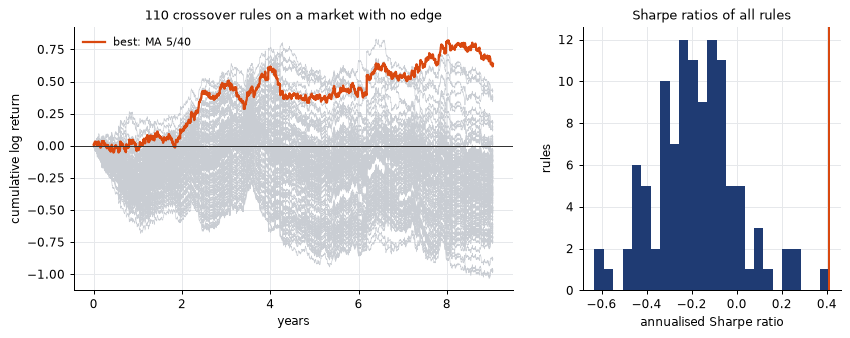

In [3]:
fig, axes = plt.subplots(
    1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.7, 1]}
)
years = np.arange(T) / PPY
cum = np.cumsum(R_noise, axis=0)
axes[0].plot(years, cum, color=LIGHT, lw=0.5)
axes[0].plot(
    years, cum[:, best], color=ORANGE, lw=1.8, label=f"best: {rule_names[best]}"
)
axes[0].axhline(0, color="#333", lw=0.8)
axes[0].set(
    xlabel="years",
    ylabel="cumulative log return",
    title="110 crossover rules on a market with no edge",
)
axes[0].legend(loc="upper left")
axes[1].hist(sr * ANN, bins=25, color=NAVY)
axes[1].axvline(sr[best] * ANN, color=ORANGE, lw=1.6)
axes[1].set(
    xlabel="annualised Sharpe ratio", ylabel="rules", title="Sharpe ratios of all rules"
)
plt.show()

In this market the best rule, a 5/40 crossover, earned an annualised Sharpe ratio of 0.41 over nine years while 86% of the rules lost money. On its own that result is suggestive rather than significant ($t = 1.2$). But this is one draw of the market. The cell below repeats the whole search on 100 independent random-walk markets and records how the best rule of each search would look if it were judged on its own.

median best Sharpe ratio: 0.45
searches whose best rule has a one-sided p-value below 5%: 34%
below 1%: 13%


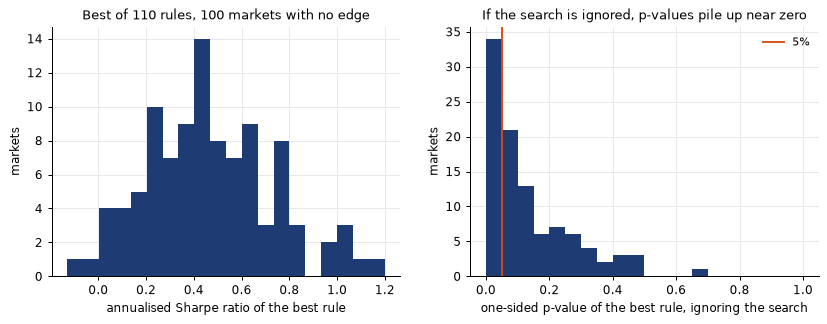

In [4]:
best_p, best_sr = [], []
for seed in range(100):
    R, _ = crossover_grid(market(trend=0.0, seed=seed))
    s = sharpe(R)
    best_sr.append(s.max() * ANN)
    best_p.append(stats.norm.sf(s.max() * math.sqrt(len(R))))
best_p, best_sr = np.array(best_p), np.array(best_sr)
print(f"median best Sharpe ratio: {np.median(best_sr):.2f}")
print(
    f"searches whose best rule has a one-sided p-value below 5%: {(best_p < 0.05).mean():.0%}"
)
print(f"below 1%: {(best_p < 0.01).mean():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(best_sr, bins=20, color=NAVY)
axes[0].set(
    xlabel="annualised Sharpe ratio of the best rule",
    ylabel="markets",
    title="Best of 110 rules, 100 markets with no edge",
)
axes[1].hist(best_p, bins=20, range=(0, 1), color=NAVY)
axes[1].axvline(0.05, color=ORANGE, lw=1.5, label="5%")
axes[1].set(
    xlabel="one-sided p-value of the best rule, ignoring the search",
    ylabel="markets",
    title="If the search is ignored, p-values pile up near zero",
)
axes[1].legend()
plt.show()

If the $p$-value of the best rule meant what it claims, it would be uniformly distributed between 0 and 1 on markets with no edge, and only 5% of searches would fall below 0.05. Instead about a third do. The reason is selection. If 110 independent rules were each tested at the 5% level, the chance that at least one passes would be $1 - 0.95^{110} \approx 99.6\%$. These rules are strongly correlated (a 20/200 crossover and a 25/200 crossover hold the same position on most days), so they behave like a much smaller number of independent tests, but the principle is the same: the more configurations a search tries, the higher its best result climbs, with or without skill.

The rest of the notebook builds up the tools that account for this. Each answers a slightly different question:

| Statistic | Question it answers |
|---|---|
| Probabilistic Sharpe ratio (PSR) | How sure can I be that this one Sharpe ratio is above a benchmark, given its sample size, skewness and kurtosis? |
| Deflated Sharpe ratio (DSR) | Is the best Sharpe ratio higher than the best of $N$ skill-less trials would be by chance? |
| Probability of backtest overfitting (PBO) | Does choosing the in-sample winner tend to pick something that is above average out of sample? |
| White's Reality Check, Hansen's SPA | Can I reject the hypothesis that *no* strategy in the search beats the benchmark? |

## 2. The Sharpe ratio is an estimate

### 2.1 Its sampling distribution

Let $r_1, \dots, r_T$ be per-period excess returns, independent and identically distributed with mean $\mu$, standard deviation $\sigma$, skewness $\gamma_3 = \mathbb{E}[(r-\mu)^3]/\sigma^3$ and kurtosis $\gamma_4 = \mathbb{E}[(r-\mu)^4]/\sigma^4$ (equal to 3 for a normal distribution). The Sharpe ratio $SR = \mu / \sigma$ is estimated by

$$\widehat{SR} = \frac{\hat\mu}{\hat\sigma}, \qquad \hat\mu = \frac{1}{T}\sum_t r_t, \qquad \hat\sigma^2 = \frac{1}{T-1}\sum_t (r_t - \hat\mu)^2.$$

Its approximate distribution follows from the delta method. Write $\widehat{SR} = g(\hat\mu, \hat\sigma^2)$ with $g(a, b) = a / \sqrt{b}$. By the central limit theorem applied to the pair $(r_t,\ (r_t - \mu)^2)$,

$$\sqrt{T}\begin{pmatrix}\hat\mu - \mu \\ \hat\sigma^2 - \sigma^2\end{pmatrix} \xrightarrow{d} \mathcal{N}\!\left(0,\ \Sigma\right), \qquad \Sigma = \begin{pmatrix}\sigma^2 & \gamma_3\sigma^3 \\ \gamma_3\sigma^3 & (\gamma_4 - 1)\sigma^4\end{pmatrix},$$

where the off-diagonal term is $\operatorname{Cov}(r, (r-\mu)^2) = \mathbb{E}[(r-\mu)^3]$ and the bottom-right term is $\operatorname{Var}((r-\mu)^2) = \mathbb{E}[(r-\mu)^4] - \sigma^4$. The gradient of $g$ at $(\mu, \sigma^2)$ is

$$\nabla g = \left(\frac{1}{\sigma},\ -\frac{\mu}{2\sigma^3}\right),$$

so $\sqrt{T}(\widehat{SR} - SR) \to \mathcal{N}(0, \nabla g^\top \Sigma\, \nabla g)$ with

$$\nabla g^\top \Sigma\, \nabla g = \frac{\sigma^2}{\sigma^2} - 2\cdot\frac{1}{\sigma}\cdot\frac{\mu}{2\sigma^3}\cdot\gamma_3\sigma^3 + \frac{\mu^2}{4\sigma^6}(\gamma_4 - 1)\sigma^4 = 1 - \gamma_3\, SR + \frac{\gamma_4 - 1}{4} SR^2 .$$

This is the result in Mertens (2002). Replacing $T$ by $T-1$, as is conventional, the standard error is

$$\sigma(\widehat{SR}) = \sqrt{\frac{1 - \gamma_3\, SR + \frac{\gamma_4 - 1}{4} SR^2}{T - 1}}.$$

For normal returns ($\gamma_3 = 0$, $\gamma_4 = 3$) this reduces to the familiar $\sqrt{(1 + SR^2/2)/(T-1)}$ of Lo (2002). Negative skewness and fat tails both widen it. Two things about the formula matter in practice:

* The corrections scale with $SR$ and $SR^2$ *per period*. A daily Sharpe ratio of 0.05 (about 0.8 a year) makes them tiny, which is why they are often ignored. For monthly data, where per-period Sharpe ratios are around 0.3, they are not.
* The formula assumes independent returns. Serial correlation changes the variance of $\hat\mu$, which is the subject of Lo (2002) and of the block bootstrap in Section 6.

In [5]:
def sharpe_moments(returns):
    """Per-period Sharpe ratio, skewness, kurtosis (3 for a normal distribution) and
    number of observations. Skewness and kurtosis are the bias-corrected estimates."""
    r = np.asarray(returns, dtype=float)
    r = r[np.isfinite(r)]
    return (
        r.mean() / r.std(ddof=1),
        stats.skew(r, bias=False),
        stats.kurtosis(r, fisher=False, bias=False),
        len(r),
    )


def sharpe_standard_error(sr, n, skew=0.0, kurtosis=3.0):
    """Standard error of a per-period Sharpe ratio estimated from n returns."""
    v = 1 - skew * sr + (kurtosis - 1) / 4 * sr**2
    return math.sqrt(v / (n - 1)) if v > 0 and n > 1 else float("nan")

The simulation below checks the formula on a 10-year monthly track record with a true annual Sharpe of 1.0. One version has normal returns. The other has the profile of a short-volatility strategy: most months are ordinary, but with probability 4% a month is drawn from a crash distribution, giving skewness of about $-1.8$ and kurtosis of about $9.3$. Both have exactly the same mean and variance.

In [6]:
def crash_returns(n, rng, p=0.04, jump=-5.0, jump_sd=1.5):
    """Mean-0, variance-1 draws: N(0,1) most of the time, N(jump, jump_sd^2) with
    probability p. Standardised with the exact mixture moments."""
    crash = rng.random(n) < p
    y = np.where(crash, rng.normal(jump, jump_sd, n), rng.normal(0, 1, n))
    m = p * jump
    v = (1 - p) + p * (jump_sd**2 + jump**2) - m**2
    return (y - m) / math.sqrt(v)


rng = np.random.default_rng(11)
y = crash_returns(10_000_000, rng)
crash_skew, crash_kurt = stats.skew(y), stats.kurtosis(y, fisher=False)
print(f"crash distribution: skewness {crash_skew:.2f}, kurtosis {crash_kurt:.2f}")

months, paths = 120, 40_000
sr_true = 1.0 / math.sqrt(12)  # per-month Sharpe for 1.0 a year
rows, samples = {}, {}
for name, draw in [
    ("normal", lambda n: rng.normal(0, 1, n)),
    ("crash-prone", lambda n: crash_returns(n, rng)),
]:
    X = sr_true + draw(paths * months).reshape(paths, months)
    s = sharpe(X, axis=1)
    g3 = stats.skew(X, axis=1, bias=False)
    g4 = stats.kurtosis(X, axis=1, fisher=False, bias=False)
    se_normal = np.sqrt((1 + s**2 / 2) / (months - 1))
    se_full = np.sqrt(
        np.maximum(1 - g3 * s + (g4 - 1) / 4 * s**2, 1e-12) / (months - 1)
    )
    k3, k4 = (0.0, 3.0) if name == "normal" else (crash_skew, crash_kurt)
    samples[name] = s
    rows[name] = {
        "sd of the estimate": s.std() * math.sqrt(12),
        "normal-returns formula": math.sqrt((1 + sr_true**2 / 2) / (months - 1))
        * math.sqrt(12),
        "full formula": sharpe_standard_error(sr_true, months, k3, k4) * math.sqrt(12),
        "coverage, normal formula": np.mean(np.abs(s - sr_true) <= 1.96 * se_normal),
        "coverage, full formula": np.mean(np.abs(s - sr_true) <= 1.96 * se_full),
        "mean estimate": s.mean() * math.sqrt(12),
    }
show_table(pd.DataFrame(rows))

crash distribution: skewness -1.80, kurtosis 9.25


,normal,crash-prone
sd of the estimate,0.324,0.429
normal-returns formula,0.324,0.324
full formula,0.324,0.413
"coverage, normal formula",0.953,0.869
"coverage, full formula",0.953,0.927
mean estimate,1.005,1.053


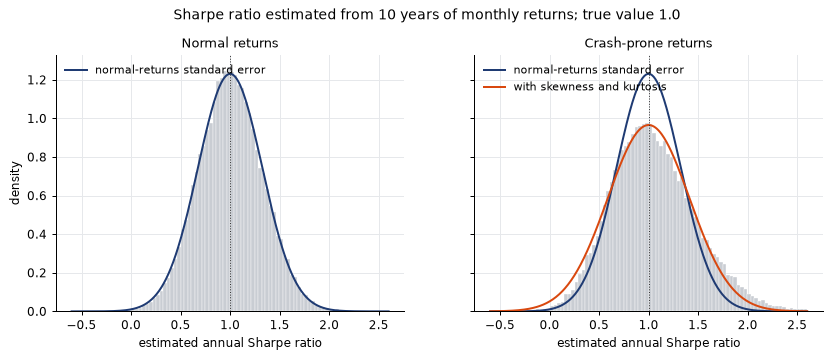

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), sharey=True)
x = np.linspace(-0.6, 2.6, 400)
se_n = math.sqrt((1 + sr_true**2 / 2) / (months - 1)) * math.sqrt(12)
se_f = sharpe_standard_error(sr_true, months, crash_skew, crash_kurt) * math.sqrt(12)
for ax, name in zip(axes, samples, strict=True):
    ax.hist(
        samples[name] * math.sqrt(12),
        bins=90,
        range=(-0.6, 2.6),
        density=True,
        color=LIGHT,
        edgecolor="white",
        lw=0.3,
    )
    ax.plot(
        x,
        stats.norm.pdf(x, 1.0, se_n),
        color=NAVY,
        lw=1.6,
        label="normal-returns standard error",
    )
    if name != "normal":
        ax.plot(
            x,
            stats.norm.pdf(x, 1.0, se_f),
            color=ORANGE,
            lw=1.6,
            label="with skewness and kurtosis",
        )
    ax.axvline(1.0, color="#333", lw=0.8, ls=":")
    ax.set(xlabel="estimated annual Sharpe ratio", title=f"{name.capitalize()} returns")
    ax.legend(loc="upper left")
axes[0].set_ylabel("density")
fig.suptitle(
    "Sharpe ratio estimated from 10 years of monthly returns; true value 1.0", y=1.02
)
plt.show()

For normal returns the formula is essentially exact: the simulated spread of the estimate and the formula agree to two decimals and a 95% interval covers the truth 95% of the time. For the crash-prone strategy the normal-returns formula understates the standard error by about a quarter (0.32 against an actual 0.43), and its "95%" interval covers the true Sharpe ratio only about 87% of the time. Using the sample skewness and kurtosis brings coverage to about 93%; the remaining shortfall comes from estimating $\gamma_3$ and $\gamma_4$ from only 120 months, which is hard precisely because crashes are rare.

The histogram also shows a bias that the formula does not capture. The crash-prone estimates are skewed to the right. A sample that happens to contain few crash months shows both a higher mean and a lower volatility than the strategy really has, so its Sharpe ratio is inflated on both counts; in a sample with extra crashes, the higher volatility cushions the fall. The mean estimate is about 1.05 rather than 1.0. A strategy with this return profile will usually *look* better than it is, which is the wrong direction for anyone allocating to it.

### 2.2 The probabilistic Sharpe ratio

Bailey and López de Prado (2012) turn the standard error into a probability. Under the normal approximation above, the probability that the true Sharpe ratio exceeds a benchmark $SR^*$, given an estimate $\widehat{SR}$, is

$$\mathrm{PSR}(SR^*) = \Phi\!\left(\frac{(\widehat{SR} - SR^*)\sqrt{T-1}}{\sqrt{1 - \hat\gamma_3\widehat{SR} + \frac{\hat\gamma_4 - 1}{4}\widehat{SR}^2}}\right).$$

Read as a frequentist statement, $1 - \mathrm{PSR}(SR^*)$ is the one-sided $p$-value of the test $H_0: SR \le SR^*$, with the standard error evaluated at the estimate. All quantities are per period. Plugging annualised Sharpe ratios into the formula with $T$ counted in days gives the wrong answer, because the skewness and kurtosis terms depend on the per-period Sharpe ratio.

### 2.3 Minimum track record length

Setting $\mathrm{PSR}(SR^*) = c$ and solving for $T$ gives the shortest track record that would make the estimate significant at confidence $c$:

$$\mathrm{MinTRL} = 1 + \left(1 - \gamma_3\widehat{SR} + \frac{\gamma_4 - 1}{4}\widehat{SR}^2\right)\left(\frac{z_c}{\widehat{SR} - SR^*}\right)^2, \qquad z_c = \Phi^{-1}(c).$$

The dependence on $(\widehat{SR} - SR^*)^{-2}$ is what makes low Sharpe ratios so hard to verify: halving the Sharpe ratio quadruples the track record needed.

In [8]:
def probabilistic_sharpe_ratio(sr, n, skew=0.0, kurtosis=3.0, benchmark=0.0):
    """Probability that the true per-period Sharpe ratio exceeds `benchmark`."""
    return stats.norm.cdf(
        (sr - benchmark) / sharpe_standard_error(sr, n, skew, kurtosis)
    )


def psr_of(returns, benchmark=0.0):
    """PSR from a return series, with its own skewness and kurtosis."""
    sr, skew, kurt, n = sharpe_moments(returns)
    return probabilistic_sharpe_ratio(sr, n, skew, kurt, benchmark)


def min_track_record_length(sr, skew=0.0, kurtosis=3.0, benchmark=0.0, confidence=0.95):
    """Observations needed for PSR(benchmark) to reach `confidence`."""
    if sr <= benchmark:
        return float("inf")
    v = 1 - skew * sr + (kurtosis - 1) / 4 * sr**2
    return 1 + v * (stats.norm.ppf(confidence) / (sr - benchmark)) ** 2

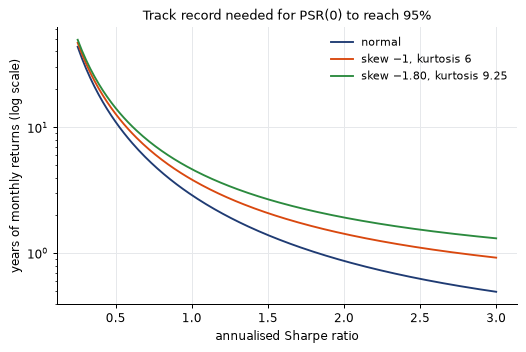

years of monthly data,Sharpe 0.5,Sharpe 1.0,Sharpe 2.0
normal,11.0,2.9,0.9
"skew −1, kurtosis 6",12.7,3.9,1.4
"skew −1.80, kurtosis 9.25",14.2,4.7,1.9


In [9]:
srs = np.linspace(0.25, 3.0, 200)
cases = [
    (0.0, 3.0, "normal"),
    (-1.0, 6.0, "skew −1, kurtosis 6"),
    (
        crash_skew,
        crash_kurt,
        f"skew {crash_skew:.2f}, kurtosis {crash_kurt:.2f}".replace("-", "−"),
    ),
]
fig, ax = plt.subplots(figsize=(6.6, 4))
mintrl = {}
for g3, g4, label in cases:
    yrs = [min_track_record_length(s / math.sqrt(12), g3, g4) / 12 for s in srs]
    ax.plot(srs, yrs, label=label)
    mintrl[label] = [
        min_track_record_length(s / math.sqrt(12), g3, g4) / 12 for s in (0.5, 1.0, 2.0)
    ]
ax.set_yscale("log")
ax.set(
    xlabel="annualised Sharpe ratio",
    ylabel="years of monthly returns (log scale)",
    title="Track record needed for PSR(0) to reach 95%",
)
ax.legend()
plt.show()
show_table(
    pd.DataFrame(mintrl, index=["Sharpe 0.5", "Sharpe 1.0", "Sharpe 2.0"]).T,
    "years of monthly data",
    "{:.1f}",
)

With normal returns a Sharpe ratio of 1.0 needs about 2.9 years of monthly data to be distinguished from zero at 95%, and a Sharpe ratio of 0.5 needs about 11. The crash-prone profile needs 4.7 years for a Sharpe of 1.0 and more than twice as long as the normal case at a Sharpe of 2.0, because the skewness and kurtosis terms grow with the Sharpe ratio. A high-Sharpe, negatively skewed track record of two or three years, which describes many option-selling funds before their first large loss, carries much less information than its headline number suggests.

## 3. How high does luck reach?

### 3.1 The maximum of $N$ Sharpe ratios

Suppose $N$ strategies all have a true Sharpe ratio of zero and their estimates are independent. From Section 2, each estimate is approximately $\mathcal{N}(0, V)$ with $V \approx 1/T$ (normal returns, $SR = 0$). The best of them, $M_N = \max_k \widehat{SR}_k$, has distribution function $\Pr(M_N \le x) = \Phi(x/\sqrt{V})^N$, so its expectation is exact and computable by one-dimensional integration:

$$\mathbb{E}[M_N] = \sqrt{V}\int_{-\infty}^{\infty} x\, N\,\phi(x)\,\Phi(x)^{N-1}\,dx .$$

Bailey and López de Prado (2014) use a closed-form approximation from extreme value theory. For large $N$, the maximum of $N$ standard normals is approximately Gumbel distributed with location $u_N$ and scale $\beta_N$. The location is the value exceeded with probability $1/N$, $u_N = \Phi^{-1}(1 - 1/N)$. The scale follows from the Gumbel distribution function $\exp(-e^{-(x-u_N)/\beta_N})$: at $x = u_N + \beta_N$ it equals $e^{-e^{-1}}$, and matching $\Phi(u_N + \beta_N)^N \approx \exp(-N(1 - \Phi(u_N+\beta_N)))$ to it gives $1 - \Phi(u_N + \beta_N) = 1/(Ne)$, so $\beta_N = \Phi^{-1}(1 - \tfrac{1}{Ne}) - \Phi^{-1}(1 - \tfrac{1}{N})$. The mean of a Gumbel distribution is $u_N + \gamma_E\beta_N$, with $\gamma_E \approx 0.5772$ the Euler–Mascheroni constant. Collecting terms:

$$\mathbb{E}[M_N] \approx SR_0 = \sqrt{V}\left((1-\gamma_E)\,\Phi^{-1}\!\left(1 - \frac{1}{N}\right) + \gamma_E\,\Phi^{-1}\!\left(1 - \frac{1}{Ne}\right)\right).$$

$SR_0$ is the Sharpe ratio that the best of $N$ skill-less strategies reaches on average. It grows roughly like $\sqrt{2\ln N}$: slowly, but without limit. The cell below compares the exact expectation, the approximation and a simulation of 20,000 searches of $N$ strategies with five years of daily returns each. For normal returns the simulation can draw each Sharpe ratio from its exact sampling distribution, because the sample mean and the sample variance are independent: $\hat\mu \sim \mathcal{N}(0, \sigma^2/T)$ and $(T-1)\hat\sigma^2/\sigma^2 \sim \chi^2_{T-1}$. That makes a large simulation cheap and its percentiles smooth.

In [10]:
def expected_max_sharpe(n_trials, sharpe_variance):
    """SR0: the expected best of n_trials per-period Sharpe ratios with no skill."""
    if n_trials < 2 or not sharpe_variance > 0:
        return 0.0
    g = np.euler_gamma
    return math.sqrt(sharpe_variance) * (
        (1 - g) * stats.norm.ppf(1 - 1 / n_trials)
        + g * stats.norm.ppf(1 - 1 / (n_trials * math.e))
    )


def expected_max_exact(n):
    """E[max of n iid standard normals], by numerical integration."""

    def density(x):
        return x * n * stats.norm.pdf(x) * stats.norm.cdf(x) ** (n - 1)

    return integrate.quad(density, -12, 12, limit=200)[0]


def simulated_sharpes(n_searches, n, T, rng):
    """Per-period Sharpe ratios of n zero-mean strategies with T normal returns each,
    drawn from the exact joint distribution of the sample mean and standard deviation."""
    mean = rng.normal(0, 1 / math.sqrt(T), (n_searches, n))
    sd = np.sqrt(rng.chisquare(T - 1, (n_searches, n)) / (T - 1))
    return mean / sd


T5 = 5 * PPY
rng = np.random.default_rng(3)
Ns = [2, 3, 5, 10, 20, 50, 100, 200, 500, 1000]
sim_mean, sim_lo, sim_hi = [], [], []
for n in Ns:
    best_sr = np.concatenate(
        [simulated_sharpes(5_000, n, T5, rng).max(axis=1) for _ in range(4)]
    )
    sim_mean.append(best_sr.mean() * ANN)
    sim_lo.append(np.quantile(best_sr, 0.05) * ANN)
    sim_hi.append(np.quantile(best_sr, 0.95) * ANN)
exact = [expected_max_exact(n) / math.sqrt(T5) * ANN for n in Ns]
approx = [expected_max_sharpe(n, 1 / T5) * ANN for n in Ns]
maxsr = pd.DataFrame(
    {
        "simulated mean": sim_mean,
        "simulated 95th percentile": sim_hi,
        "exact mean": exact,
        "SR0 approximation": approx,
    },
    index=Ns,
)
maxsr["approximation error"] = maxsr["SR0 approximation"] / maxsr["exact mean"] - 1
show_table(
    maxsr,
    "N",
    {c: "{:.3f}" for c in maxsr.columns[:-1]} | {"approximation error": "{:+.1%}"},
)

N,simulated mean,simulated 95th percentile,exact mean,SR0 approximation,approximation error
2,0.253,0.878,0.252,0.232,-7.9%
3,0.382,0.962,0.378,0.381,+0.8%
5,0.522,1.035,0.520,0.533,+2.5%
10,0.687,1.149,0.688,0.704,+2.3%
20,0.834,1.249,0.835,0.850,+1.8%
50,1.006,1.380,1.006,1.018,+1.2%
100,1.123,1.472,1.121,1.132,+0.9%
200,1.231,1.558,1.228,1.237,+0.7%
500,1.361,1.665,1.358,1.365,+0.5%
1000,1.454,1.745,1.450,1.456,+0.4%


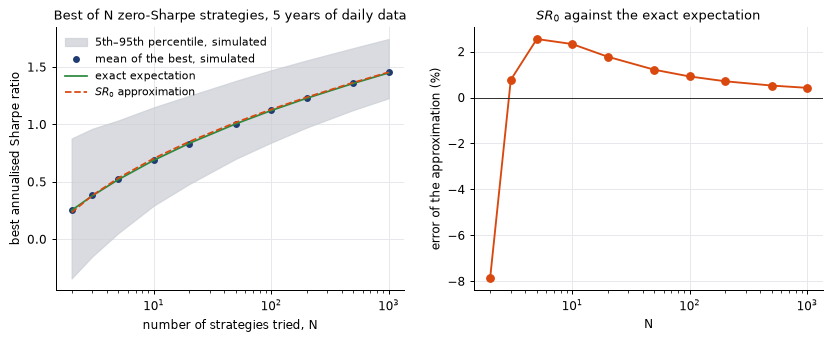

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.fill_between(
    Ns, sim_lo, sim_hi, color=LIGHT, alpha=0.7, label="5th–95th percentile, simulated"
)
ax.plot(Ns, sim_mean, "o", color=NAVY, ms=4.5, label="mean of the best, simulated")
ax.plot(Ns, exact, color=GREEN, lw=1.4, label="exact expectation")
ax.plot(Ns, approx, color=ORANGE, lw=1.4, ls="--", label=r"$SR_0$ approximation")
ax.set_xscale("log")
ax.set(
    xlabel="number of strategies tried, N",
    ylabel="best annualised Sharpe ratio",
    title="Best of N zero-Sharpe strategies, 5 years of daily data",
)
ax.legend(loc="upper left")
ax = axes[1]
ax.plot(Ns, 100 * maxsr["approximation error"], "o-", color=ORANGE)
ax.axhline(0, color="#333", lw=0.8)
ax.set_xscale("log")
ax.set(
    xlabel="N",
    ylabel="error of the approximation (%)",
    title=r"$SR_0$ against the exact expectation",
)
plt.show()

The approximation understates the expected maximum of two trials by about 8%, but from three trials on it is within about 2.5% of the exact value and beyond a hundred trials within 1%. The shaded band matters more in practice: with 100 strategies and five years of data, the best annualised Sharpe ratio from pure luck averages 1.1, and one search in twenty produces a best Sharpe ratio above about 1.5.

### 3.2 Correlated trials

Real searches do not produce independent trials. Variations of one idea share most of their positions, and their Sharpe ratios move together. Model this with a common factor: strategy $k$ has returns $x_{k,t} = \sqrt{\rho}\, z_t + \sqrt{1-\rho}\, \varepsilon_{k,t}$, with $z$ and $\varepsilon$ independent standard normals. To first order the Sharpe estimates inherit the same structure,

$$\widehat{SR}_k \approx \sqrt{\rho}\,\bar z + \sqrt{1-\rho}\,\bar\varepsilon_k, \qquad \max_k \widehat{SR}_k \approx \sqrt{\rho}\,\bar z + \sqrt{1-\rho}\,\max_k \bar\varepsilon_k ,$$

and since $\mathbb{E}[\bar z] = 0$ the expected maximum is $\sqrt{1-\rho}$ times the independent case. The key observation is that the *cross-sectional* variance of the $N$ estimates in one sample is also about $(1-\rho)/T$, because the common term $\sqrt\rho\,\bar z$ shifts every estimate by the same amount and contributes nothing to their dispersion. So if $V$ in $SR_0$ is taken to be the sample variance of the trials' Sharpe ratios, rather than the theoretical $1/T$, the correlation is accounted for automatically. This is how the deflated Sharpe ratio is defined, and the simulation below confirms it (at high correlation the best Sharpe ratio varies a lot from sample to sample, because the common factor moves every strategy together, so the agreement there is within simulation error rather than exact). It also shows the limit of the argument: when the trials form clusters (here 10 groups of 10 strategies, correlation 0.9 within a group and 0 between groups), the sample variance mixes within- and between-cluster dispersion and $SR_0$ overstates the expected maximum, which makes the test conservative rather than lenient.

In [12]:
rng = np.random.default_rng(4)
n, reps = 100, 1000
rows = {}
for label, rho in [
    ("ρ = 0", 0.0),
    ("ρ = 0.3", 0.3),
    ("ρ = 0.6", 0.6),
    ("ρ = 0.9", 0.9),
    ("10 clusters", None),
]:
    best_sr, thr = [], []
    for _ in range(reps):
        if rho is None:
            common = np.repeat(rng.normal(size=(T5, 10)), 10, axis=1)
            X = math.sqrt(0.9) * common + math.sqrt(0.1) * rng.normal(size=(T5, n))
        else:
            X = math.sqrt(rho) * rng.normal(size=(T5, 1)) + math.sqrt(
                1 - rho
            ) * rng.normal(size=(T5, n))
        s = sharpe(X)
        best_sr.append(s.max())
        thr.append(expected_max_sharpe(n, s.var(ddof=1)))
    rows[label] = {
        "mean best (simulated)": np.mean(best_sr) * ANN,
        "SR0 with sample variance": np.mean(thr) * ANN,
        "SR0 assuming independence": expected_max_sharpe(n, 1 / T5) * ANN,
    }
corr = pd.DataFrame(rows).T
show_table(corr, "", "{:.3f}")

,mean best (simulated),SR0 with sample variance,SR0 assuming independence
ρ = 0,1.121,1.130,1.132
ρ = 0.3,0.955,0.945,1.132
ρ = 0.6,0.705,0.715,1.132
ρ = 0.9,0.350,0.356,1.132
10 clusters,0.871,1.057,1.132


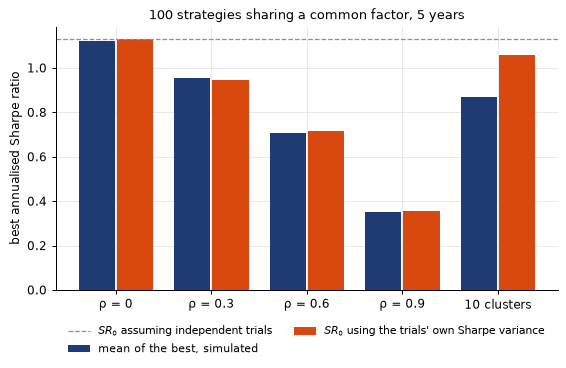

In [13]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
xpos = np.arange(len(corr))
ax.bar(
    xpos - 0.2,
    corr["mean best (simulated)"],
    0.38,
    color=NAVY,
    label="mean of the best, simulated",
)
ax.bar(
    xpos + 0.2,
    corr["SR0 with sample variance"],
    0.38,
    color=ORANGE,
    label=r"$SR_0$ using the trials' own Sharpe variance",
)
ax.axhline(
    corr["SR0 assuming independence"].iloc[0],
    color=GREY,
    ls="--",
    lw=1,
    label=r"$SR_0$ assuming independent trials",
)
ax.set_xticks(xpos, corr.index)
ax.set(
    ylabel="best annualised Sharpe ratio",
    title="100 strategies sharing a common factor, 5 years",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
plt.show()

## 4. The deflated Sharpe ratio

The deflated Sharpe ratio (Bailey and López de Prado, 2014) combines the two previous sections. Having chosen strategy $k^*$ as the best of $N$ trials, ask whether its true Sharpe ratio exceeds what the best of $N$ skill-less trials would reach on average:

$$\mathrm{DSR} = \mathrm{PSR}(SR_0) = \Phi\!\left(\frac{(\widehat{SR}_{k^*} - SR_0)\sqrt{T-1}}{\sqrt{1 - \hat\gamma_3\widehat{SR}_{k^*} + \frac{\hat\gamma_4 - 1}{4}\widehat{SR}_{k^*}^2}}\right),$$

$$SR_0 = \sqrt{\hat V}\left((1-\gamma_E)\,\Phi^{-1}\!\left(1-\tfrac{1}{N}\right) + \gamma_E\,\Phi^{-1}\!\left(1-\tfrac{1}{Ne}\right)\right),$$

where $\hat V$ is the sample variance of the $N$ trials' per-period Sharpe ratios and $\hat\gamma_3, \hat\gamma_4$ are the skewness and kurtosis of the selected strategy's returns. A value above 0.95 is the conventional bar. Section 8.4 shows a case where $\hat V$ is the wrong input and the null value $1/T$ is the better one.

In [14]:
@dataclass(frozen=True)
class DeflatedSharpe:
    dsr: float
    sharpe: float  # per period, of the selected strategy
    threshold: float  # SR0, per period
    n_trials: int

    def annualised(self, periods_per_year):
        k = math.sqrt(periods_per_year)
        return self.sharpe * k, self.threshold * k


def deflated_sharpe_ratio(returns, n_trials, trial_sharpes=None, sharpe_variance=None):
    """DSR of the selected strategy's returns after n_trials trials. The variance in SR0 is
    the sample variance of `trial_sharpes` unless `sharpe_variance` is given."""
    sr, skew, kurt, n = sharpe_moments(returns)
    if sharpe_variance is None:
        sharpe_variance = np.var(np.asarray(trial_sharpes, dtype=float), ddof=1)
    sr0 = expected_max_sharpe(n_trials, sharpe_variance)
    return DeflatedSharpe(
        probabilistic_sharpe_ratio(sr, n, skew, kurt, sr0), sr, sr0, n_trials
    )

Two details deserve emphasis. First, $N$ must be the number of configurations *actually tried*, including those discarded along the way and those tried in earlier projects on the same data. The statistic cannot detect under-reporting; it is only as honest as its input. Second, the benchmark $SR_0$ is the *mean* of the null distribution of the maximum, and the DSR then asks for the selected Sharpe ratio to clear it by a further 1.65 standard errors. That is a stricter requirement than controlling the family-wise error rate at 5%, and Section 6.4 shows the consequence: very few false positives, but also less power than the bootstrap tests.

The chart shows how quickly a fixed backtest result loses significance as the number of trials behind it grows, for five years of daily returns.

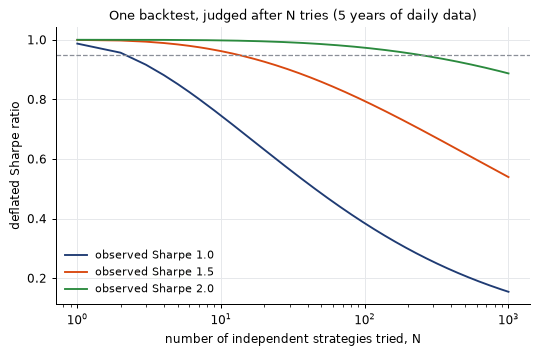

trials after which DSR falls below 0.95: {1.0: 3, 1.5: 14, 2.0: 237}


In [15]:
Ns_dsr = np.arange(1, 1001)
fig, ax = plt.subplots(figsize=(6.8, 4))
crossings = {}
for s_ann in (1.0, 1.5, 2.0):
    s = s_ann / ANN
    vals = [
        probabilistic_sharpe_ratio(s, T5, 0, 3, expected_max_sharpe(n, 1 / T5))
        for n in Ns_dsr
    ]
    ax.plot(Ns_dsr, vals, label=f"observed Sharpe {s_ann:.1f}")
    crossings[s_ann] = next(
        (int(n) for n, v in zip(Ns_dsr, vals, strict=True) if v < 0.95), None
    )
ax.axhline(0.95, color=GREY, ls="--", lw=1)
ax.set_xscale("log")
ax.set(
    xlabel="number of independent strategies tried, N",
    ylabel="deflated Sharpe ratio",
    title="One backtest, judged after N tries (5 years of daily data)",
)
ax.legend(loc="lower left")
plt.show()
print("trials after which DSR falls below 0.95:", crossings)

An annualised Sharpe ratio of 1.0 over five years is significant if it was the only thing tried, and stops being significant at three independent tries. A Sharpe ratio of 1.5 falls below the bar at 14 tries, and 2.0 at 237.

Applied to the noise search from Section 1:

In [16]:
d = deflated_sharpe_ratio(R_noise[:, best], n_trials=N, trial_sharpes=sr)
sr_ann, sr0_ann = d.annualised(PPY)
print(
    f"best Sharpe {sr_ann:.2f} against an expected best-of-{N} from luck of {sr0_ann:.2f}"
)
print(f"PSR(0) of the best rule alone: {psr_of(R_noise[:, best]):.3f}")
print(f"deflated Sharpe ratio: {d.dsr:.3f}")

best Sharpe 0.41 against an expected best-of-110 from luck of 0.48
PSR(0) of the best rule alone: 0.896
deflated Sharpe ratio: 0.419


## 5. The probability of backtest overfitting

The deflated Sharpe ratio asks whether the winner is better than luck. Bailey, Borwein, López de Prado and Zhu (2017) ask a different question: does the *selection procedure* (pick the strategy with the best in-sample Sharpe ratio) tend to pick strategies that do well out of sample? If it does not, the search has overfit, whatever the winner's in-sample number says.

### 5.1 Combinatorially symmetric cross-validation

Let $R$ be the $T \times N$ matrix of per-period returns of every trial. CSCV estimates the out-of-sample behaviour of the in-sample winner using every way of splitting the data in half:

1. Partition the $T$ rows into $S$ consecutive blocks of (almost) equal size, $S$ even.
2. For each of the $\binom{S}{S/2}$ ways of choosing $S/2$ blocks, call those rows the training set $J$ and the remaining rows the test set $\bar J$. Every split has a mirror image with the roles reversed, which is what makes the scheme symmetric.
3. In each split, find the trial with the highest Sharpe ratio on $J$, $n^* = \arg\max_n \widehat{SR}_n(J)$.
4. Rank all $N$ trials by their Sharpe ratio on $\bar J$, and let $r^*$ be the rank of $n^*$ (1 = worst, $N$ = best). Convert it to a relative rank $\omega = r^*/(N+1) \in (0, 1)$ and a logit $\lambda = \ln\frac{\omega}{1-\omega}$.
5. The probability of backtest overfitting is the share of splits in which the in-sample winner finishes in the bottom half out of sample:

$$\mathrm{PBO} = \Pr(\lambda \le 0) = \frac{1}{\binom{S}{S/2}}\sum_{\text{splits}} \mathbf{1}\{\lambda \le 0\}.$$

If the trials have no skill, the in-sample winner's out-of-sample rank is uniform on $\{1, \dots, N\}$ and PBO is about one half. If the winner's edge is real and distinguishable, it stays near the top out of sample and PBO approaches zero. Two further summaries come from the same splits: the slope of the winner's out-of-sample Sharpe ratio on its in-sample Sharpe ratio (negative means that a better in-sample result predicts a *worse* one out of sample, the signature of fitting noise), and the probability that the winner loses money out of sample.

With $S = 16$ there are 12,870 splits. Computing a Sharpe ratio on half of the rows for every trial in every split would be slow done directly; the implementation precomputes the sum and sum of squares of each trial in each block, after which every split's Sharpe ratios are a matrix product. The grid below shows the splits for a small case, $S = 6$ (20 splits), to make the construction concrete.

In [17]:
@dataclass(frozen=True)
class PBOResult:
    pbo: float
    logits: np.ndarray = field(repr=False)
    is_sharpe: np.ndarray = field(
        repr=False
    )  # the in-sample winner, in sample, per split
    oos_sharpe: np.ndarray = field(repr=False)  # the same strategy out of sample
    slope: float  # of out-of-sample on in-sample Sharpe ratio
    prob_oos_loss: float
    n_splits: int


def probability_of_backtest_overfitting(R, n_blocks=16):
    """PBO by CSCV for a T x N matrix of per-period returns (one column per trial)."""
    R = np.asarray(R, dtype=float)
    T, N = R.shape
    splits = np.array(list(combinations(range(n_blocks), n_blocks // 2)))
    blocks = np.array_split(np.arange(T), n_blocks)
    s1 = np.stack([R[b].sum(0) for b in blocks])  # per-block sums ...
    s2 = np.stack([(R[b] ** 2).sum(0) for b in blocks])  # ... and sums of squares
    count = np.array([len(b) for b in blocks], dtype=float)[:, None]
    train = np.zeros((len(splits), n_blocks))
    train[np.arange(len(splits))[:, None], splits] = 1.0

    def split_sharpe(
        mask,
    ):  # Sharpe ratio of every trial on the rows selected by `mask`
        n = mask @ count
        mean = mask @ s1 / n
        var = (mask @ s2 - n * mean**2) / (n - 1)
        return mean / np.sqrt(var)

    sr_in, sr_out = split_sharpe(train), split_sharpe(1.0 - train)
    rows = np.arange(len(splits))
    winner = sr_in.argmax(axis=1)
    rank = (sr_out < sr_out[rows, winner][:, None]).sum(
        axis=1
    ) + 1  # 1 = worst, N = best
    omega = rank / (N + 1)
    logits = np.log(omega / (1 - omega))
    is_best, oos_best = sr_in[rows, winner], sr_out[rows, winner]
    return PBOResult(
        pbo=float(np.mean(logits <= 0)),
        logits=logits,
        is_sharpe=is_best,
        oos_sharpe=oos_best,
        slope=float(np.polyfit(is_best, oos_best, 1)[0]),
        prob_oos_loss=float(np.mean(oos_best < 0)),
        n_splits=len(splits),
    )

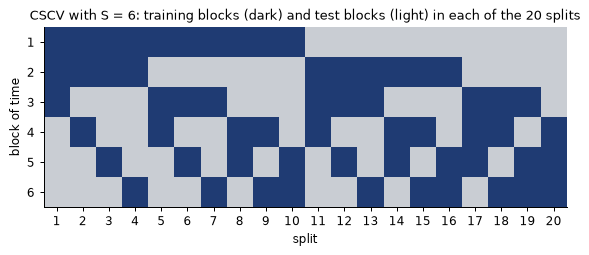

In [18]:
S_demo = 6
splits = list(combinations(range(S_demo), S_demo // 2))
grid = np.zeros((len(splits), S_demo))
for i, c in enumerate(splits):
    grid[i, list(c)] = 1
fig, ax = plt.subplots(figsize=(7.5, 2.6))
ax.imshow(grid.T, aspect="auto", cmap=mpl.colors.ListedColormap([LIGHT, NAVY]))
ax.set(
    xlabel="split",
    ylabel="block of time",
    title=f"CSCV with S = {S_demo}: training blocks (dark) and test blocks (light) in each of the {len(splits)} splits",
)
ax.set_yticks(range(S_demo), [f"{b + 1}" for b in range(S_demo)])
ax.set_xticks(range(len(splits)), [str(i + 1) for i in range(len(splits))])
ax.grid(False)
plt.show()

### 5.2 Noise against a real edge

To see the difference, rerun the crossover search of Section 1 on two markets: the original random walk, and a market with a genuine but modest trend (a daily drift of up to 0.15% whose sign follows a slow random walk, so it persists for months). The left-hand panels plot the in-sample winner's out-of-sample Sharpe ratio against its in-sample Sharpe ratio for the 12,870 splits (a random 4,000 of them are drawn; the fitted line uses all of them); the right-hand panels show the distribution of $\lambda$.

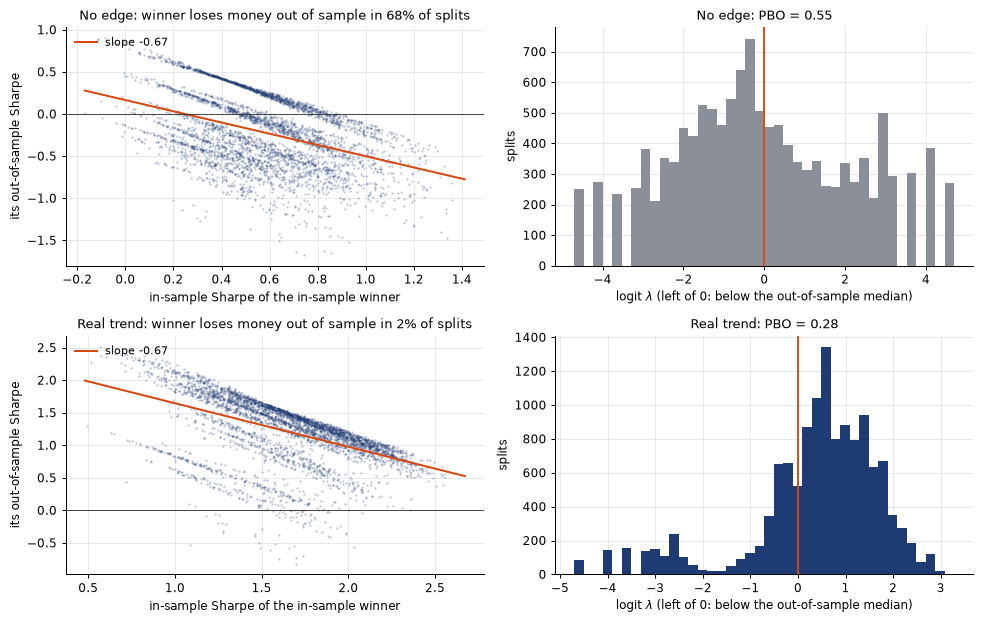

In [19]:
R_trend, _ = crossover_grid(market(trend=0.0015, seed=1))
pbo_runs = {
    "No edge": probability_of_backtest_overfitting(R_noise),
    "Real trend": probability_of_backtest_overfitting(R_trend),
}
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, (label, res) in enumerate(pbo_runs.items()):
    isr, osr = res.is_sharpe * ANN, res.oos_sharpe * ANN
    ax = axes[row, 0]
    show = np.random.default_rng(0).choice(
        len(isr), 4000, replace=False
    )  # lighter chart
    ax.scatter(isr[show], osr[show], s=3, alpha=0.3, color=NAVY, lw=0)
    b = np.polyfit(isr, osr, 1)
    xs = np.linspace(isr.min(), isr.max(), 10)
    ax.plot(xs, np.polyval(b, xs), color=ORANGE, lw=1.6, label=f"slope {b[0]:.2f}")
    ax.axhline(0, color="#333", lw=0.7)
    ax.set(
        xlabel="in-sample Sharpe of the in-sample winner",
        ylabel="its out-of-sample Sharpe",
        title=f"{label}: winner loses money out of sample in {res.prob_oos_loss:.0%} of splits",
    )
    ax.legend(loc="upper left")
    ax = axes[row, 1]
    ax.hist(res.logits, bins=40, color=NAVY if res.pbo < 0.5 else GREY)
    ax.axvline(0, color=ORANGE, lw=1.5)
    ax.set(
        xlabel=r"logit $\lambda$ (left of 0: below the out-of-sample median)",
        ylabel="splits",
        title=f"{label}: PBO = {res.pbo:.2f}",
    )
fig.tight_layout()
plt.show()

On the random walk the in-sample winner is below the out-of-sample median in 55% of splits and loses money out of sample in about two thirds of them. On the trending market PBO falls to 0.28 and the winner almost never loses money out of sample. Notice that the slope is negative in *both* cases, and that the points form parallel bands with slopes close to $-1$. That is largely mechanical. CSCV splits one fixed sample into two halves, so for any one rule the in-sample and out-of-sample Sharpe ratios roughly average to its full-sample Sharpe ratio: a split that flatters one half penalises the other. Each band is one rule that wins in many splits, and the fitted line runs across the bands. A negative slope on its own is therefore not evidence of overfitting. What matters is where the bands sit, which is what PBO and the probability of an out-of-sample loss summarise.

### 5.3 What PBO measures, and what it does not

PBO is a statement about the *ranking* of trials, not about whether any of them is profitable. The simulation below makes that concrete with 50 strategies and five years of daily data in three situations: no edge anywhere; one strategy with a real edge among 49 without one; and all 50 sharing the same edge.

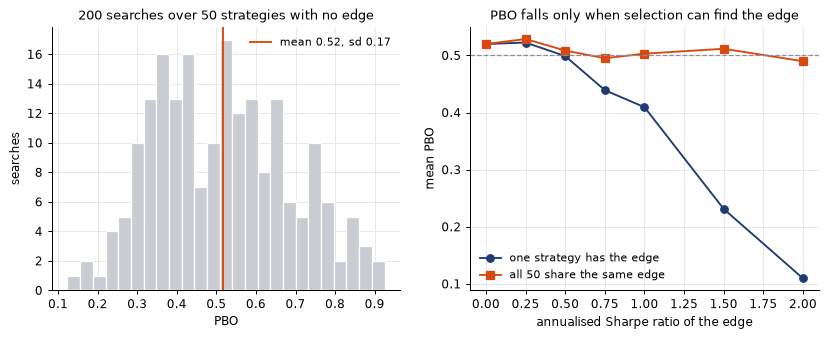

In [20]:
rng = np.random.default_rng(5)
null_pbo = [
    probability_of_backtest_overfitting(rng.normal(0, 0.01, (T5, 50))).pbo
    for _ in range(200)
]
edges = [0.0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0]
one_good, all_good = [], []
for e in edges:
    a, b = [], []
    for _ in range(60):
        X = rng.normal(0, 0.01, (T5, 50))
        a.append(
            probability_of_backtest_overfitting(
                np.column_stack([X[:, 0] + e / ANN * 0.01, X[:, 1:]])
            ).pbo
        )
        b.append(probability_of_backtest_overfitting(X + e / ANN * 0.01).pbo)
    one_good.append(np.mean(a))
    all_good.append(np.mean(b))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(null_pbo, bins=25, color=LIGHT, edgecolor="white")
axes[0].axvline(
    np.mean(null_pbo),
    color=ORANGE,
    lw=1.5,
    label=f"mean {np.mean(null_pbo):.2f}, sd {np.std(null_pbo):.2f}",
)
axes[0].set(
    xlabel="PBO",
    ylabel="searches",
    title="200 searches over 50 strategies with no edge",
)
axes[0].legend()
axes[1].plot(edges, one_good, "o-", color=NAVY, label="one strategy has the edge")
axes[1].plot(edges, all_good, "s-", color=ORANGE, label="all 50 share the same edge")
axes[1].axhline(0.5, color=GREY, ls="--", lw=1)
axes[1].set(
    xlabel="annualised Sharpe ratio of the edge",
    ylabel="mean PBO",
    title="PBO falls only when selection can find the edge",
)
axes[1].legend()
plt.show()

Three lessons follow. Under pure noise PBO is centred on one half but varies a lot from one search to the next (standard deviation about 0.17), so a single PBO of 0.35 is weak evidence of anything. When one strategy has a real edge, PBO falls as the edge grows, because the selection step starts finding it. And when every strategy shares the same edge, PBO stays at one half however large the edge is: all the strategies are equally good, so which one wins in-sample is a coin toss, and choosing the winner adds nothing. The search has not overfit in any harmful sense, yet PBO cannot tell this case apart from pure noise. PBO should therefore be read next to a test of whether anything works at all, which is the subject of the next section.

## 6. Data-snooping tests: White and Hansen

### 6.1 The hypothesis and White's Reality Check

Let $d_{k,t}$ be the return of strategy $k$ in period $t$ in excess of a benchmark (cash, buy-and-hold, or an equal-weight portfolio), with means $\mu_k = \mathbb{E}[d_{k,t}]$. The question "is the best strategy genuinely better than the benchmark?" becomes a test of the *composite* null hypothesis

$$H_0:\ \max_{k = 1,\dots,N} \mu_k \le 0 .$$

White (2000) uses the statistic $W = \sqrt{T}\max_k \bar d_k$. Its distribution under $H_0$ depends on all of the unknown $\mu_k$, which is what makes composite nulls hard. White's solution is to use the *least favourable* configuration, $\mu_1 = \dots = \mu_N = 0$, under which rejections are most likely; a test with the right size there has at most that size anywhere in $H_0$. Under that configuration $\sqrt{T}(\bar d - \mu)$ is approximately multivariate normal with the long-run covariance of the $d_{k,t}$, and its distribution, including all correlations between the strategies, is estimated by resampling time periods:

$$W^{*(b)} = \sqrt{T}\max_k\left(\bar d_k^{*(b)} - \bar d_k\right), \qquad b = 1,\dots,B, \qquad p = \frac{1}{B}\sum_b \mathbf 1\{W^{*(b)} \ge W\}.$$

Resampling whole time periods keeps the cross-sectional dependence between strategies intact, which is the main advantage over Bonferroni-type corrections when the strategies are correlated.

### 6.2 The stationary bootstrap and the long-run variance

Strategy returns are rarely independent over time: positions persist, so do volatility regimes. Resampling single days would destroy that dependence and understate the variance of the means. Politis and Romano (1994) resample *blocks* of consecutive observations whose lengths are geometric with mean $1/p$: each resampled observation either continues the current block (probability $1-p$) or jumps to a uniformly random new start (probability $p$), wrapping around the end of the sample. Random block lengths make the resampled series stationary, unlike fixed-length blocks.

Politis and Romano (1994, Lemma 1) give the variance of $\sqrt{T}\,\bar d^*$ under this scheme in closed form:

$$\hat\omega^2 = \hat c_0 + 2\sum_{i=1}^{T-1}\kappa_i\,\hat c_i, \qquad \kappa_i = \left(1 - \frac{i}{T}\right)(1-p)^i + \frac{i}{T}(1-p)^{T-i},$$

where $\hat c_i$ is the sample autocovariance at lag $i$. The factor $(1-p)^i$ is the probability that two resampled observations $i$ periods apart come from the same block; the second term comes from blocks that wrap around the end of the sample. This is a kernel estimate of the long-run variance with weights that decay geometrically; it is used below to studentise SPA, and Appendix A checks the FFT implementation against the sum written out term by term.

In [21]:
def stationary_bootstrap_indices(T, mean_block, reps, rng):
    """reps x T matrix of resampled row indices: geometric blocks with mean `mean_block`,
    wrapping around the end of the sample."""
    p = 1.0 / mean_block
    idx = np.empty((reps, T), dtype=np.int64)
    idx[:, 0] = rng.integers(0, T, reps)
    new_block = rng.random((reps, T)) < p
    starts = rng.integers(0, T, (reps, T))
    for t in range(1, T):
        idx[:, t] = np.where(new_block[:, t], starts[:, t], (idx[:, t - 1] + 1) % T)
    return idx


def bootstrap_means(X, mean_block, reps, rng, chunk=100):
    """reps x N column means of stationary-bootstrap resamples of X. Each resample is stored
    as a count of how often each row was drawn, so memory is chunk x T, not chunk x T x N."""
    T = X.shape[0]
    out = np.empty((reps, X.shape[1]))
    for s in range(0, reps, chunk):
        k = min(chunk, reps - s)
        idx = stationary_bootstrap_indices(T, mean_block, k, rng)
        counts = np.bincount((idx + np.arange(k)[:, None] * T).ravel(), minlength=k * T)
        out[s : s + k] = counts.reshape(k, T) @ X / T
    return out


def long_run_variance(X, mean_block):
    """Variance of sqrt(T) times each column mean under the stationary bootstrap."""
    X = np.asarray(X, dtype=float)
    T = X.shape[0]
    Xc = X - X.mean(0)
    f = np.fft.rfft(Xc, n=2 * T, axis=0)
    acov = (
        np.fft.irfft(f * np.conj(f), axis=0)[:T] / T
    )  # autocovariances, lags 0 .. T-1
    i = np.arange(1, T)
    p = 1.0 / mean_block
    kappa = (1 - i / T) * (1 - p) ** i + (i / T) * (1 - p) ** (T - i)
    return acov[0] + 2 * (kappa[:, None] * acov[1:]).sum(0)


@dataclass(frozen=True)
class RealityCheck:
    p_value: float
    statistic: float
    reps: int


def white_reality_check(X, reps=2000, mean_block=10.0, seed=None):
    """White's Reality Check for a T x N matrix of returns in excess of the benchmark."""
    X = np.asarray(X, dtype=float)
    T = X.shape[0]
    d = X.mean(0)
    null = math.sqrt(T) * (
        bootstrap_means(X, mean_block, reps, np.random.default_rng(seed)) - d
    ).max(axis=1)
    stat = math.sqrt(T) * d.max()
    return RealityCheck(float(np.mean(null >= stat)), stat, reps)


# Hansen's test for superior predictive ability, explained in Section 6.3
@dataclass(frozen=True)
class SPA:
    p_value: float  # Hansen's consistent p-value
    p_lower: float
    p_upper: float
    statistic: float
    reps: int


def hansen_spa(X, reps=2000, mean_block=10.0, seed=None):
    """Hansen's test for superior predictive ability, with its lower and upper bounds."""
    X = np.asarray(X, dtype=float)
    T, N = X.shape
    d = X.mean(0)
    dstar = bootstrap_means(X, mean_block, reps, np.random.default_rng(seed))
    omega = np.sqrt(long_run_variance(X, mean_block))
    t = math.sqrt(T) * d / omega
    stat = max(0.0, t.max())
    clearly_bad = t <= -math.sqrt(2 * math.log(math.log(T)))

    def p_value(mu):
        null = np.maximum(0.0, (math.sqrt(T) * (dstar - d + mu) / omega).max(axis=1))
        return float(np.mean(null >= stat))

    return SPA(
        p_value(np.where(clearly_bad, d, 0.0)),
        p_value(np.minimum(d, 0.0)),
        p_value(np.zeros(N)),
        stat,
        reps,
    )

The choice of $p$ matters. The simulation below generates returns with no edge but with first-order autocorrelation 0.3 (20 strategies, five years, 200 repetitions) and records how often each test rejects at 5% for different mean block lengths $1/p$.

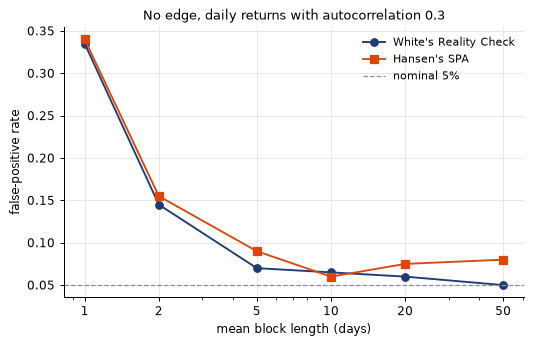

mean block length (days),Reality Check,SPA
1,33.5%,34.0%
2,14.5%,15.5%
5,7.0%,9.0%
10,6.5%,6.0%
20,6.0%,7.5%
50,5.0%,8.0%


In [22]:
rng = np.random.default_rng(9)
phi, blocks, n_markets = 0.3, [1, 2, 5, 10, 20, 50], 200
ar_markets = []
for _ in range(n_markets):
    e = rng.normal(0, 0.01, (T5 + 200, 20))
    xar = np.empty_like(e)
    xar[0] = e[0]
    for t in range(1, len(e)):
        xar[t] = phi * xar[t - 1] + e[t]
    ar_markets.append(xar[200:])
size_rc = [
    np.mean([white_reality_check(m, 500, b, seed=0).p_value < 0.05 for m in ar_markets])
    for b in blocks
]
size_spa = [
    np.mean([hansen_spa(m, 500, b, seed=0).p_value < 0.05 for m in ar_markets])
    for b in blocks
]
fig, ax = plt.subplots(figsize=(6.6, 3.9))
ax.plot(blocks, size_rc, "o-", label="White's Reality Check")
ax.plot(blocks, size_spa, "s-", label="Hansen's SPA")
ax.axhline(0.05, color=GREY, ls="--", lw=1, label="nominal 5%")
ax.set_xscale("log")
ax.set_xticks(blocks, [str(b) for b in blocks])
ax.set(
    xlabel="mean block length (days)",
    ylabel="false-positive rate",
    title=f"No edge, daily returns with autocorrelation {phi}",
)
ax.legend()
plt.show()
show_table(
    pd.DataFrame({"Reality Check": size_rc, "SPA": size_spa}, index=blocks),
    "mean block length (days)",
    "{:.1%}",
)

With blocks of one day (an ordinary i.i.d. bootstrap) both tests reject a true null about a third of the time, because the variance of the mean of a positively autocorrelated series is $(1+\phi)/(1-\phi) \approx 1.9$ times larger than the i.i.d. formula assumes. From blocks of about five days the false-positive rate is between 5% and 9%, close to the nominal 5% given simulation error of about 1.5 percentage points. Ten days, the default here, is a reasonable choice for daily strategy returns; strategies that hold positions for months may need longer blocks.

### 6.3 Hansen's test for superior predictive ability

The Reality Check has two weaknesses, both caused by the least favourable configuration. First, the maximum in $W^*$ is taken over raw means, so a strategy with high variance dominates the bootstrap distribution whether or not it is any good. Second, strategies that are clearly worse than the benchmark are treated as if they had $\mu_k = 0$; they cannot be the best, but they still push up the null distribution of the maximum. Adding poor strategies to a search therefore makes it harder to detect a good one, which is a perverse property for a test.

Hansen (2005) fixes both. The statistic is studentised by the long-run standard deviation from 6.2,

$$T_{SPA} = \max\left(0,\ \max_k \frac{\sqrt{T}\,\bar d_k}{\hat\omega_k}\right),$$

and the null distribution recentres each strategy at an estimate of the most favourable mean consistent with $H_0$:

$$T^{*(b)}_{SPA} = \max\left(0,\ \max_k \frac{\sqrt{T}\left(\bar d_k^{*(b)} - \bar d_k + \hat\mu_k\right)}{\hat\omega_k}\right), \qquad \hat\mu_k = \bar d_k\,\mathbf 1\left\{\frac{\sqrt{T}\,\bar d_k}{\hat\omega_k} \le -\sqrt{2\ln\ln T}\right\}.$$

A strategy whose $t$-statistic is below $-\sqrt{2\ln\ln T}$ (about $-2.0$ for five years of daily data) is recentred at its own negative mean, which keeps it out of the way of the maximum. The threshold shrinks to zero relative to $\sqrt{T}$, so asymptotically only strategies that really are worse than the benchmark are moved. Setting $\hat\mu_k = 0$ for all $k$ gives a conservative upper bound (the studentised Reality Check) and $\hat\mu_k = \min(\bar d_k, 0)$ a liberal lower bound; `hansen_spa`, defined with the bootstrap in Section 6.2, reports all three.

The simulation below takes one strategy with a true annual Sharpe ratio of 1.0 among 20 noise strategies, then adds strategies that are clearly bad: annual Sharpe ratio $-0.5$ and three times the volatility.

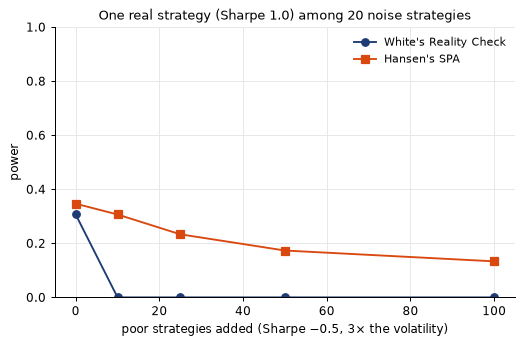

poor strategies added,Reality Check,SPA
0,30.7%,34.7%
10,0.0%,30.7%
25,0.0%,23.3%
50,0.0%,17.3%
100,0.0%,13.3%


In [23]:
rng = np.random.default_rng(8)
added, n_markets = [0, 10, 25, 50, 100], 150
power_rc, power_spa = [], []
for k in added:
    hits_rc = hits_spa = 0
    for _ in range(n_markets):
        X = np.hstack(
            [
                rng.normal(1.0 / ANN * 0.01, 0.01, (T5, 1)),
                rng.normal(0, 0.01, (T5, 20)),
                rng.normal(-0.5 / ANN * 0.03, 0.03, (T5, k)),
            ]
        )
        hits_rc += white_reality_check(X, 500, 10, seed=0).p_value < 0.05
        hits_spa += hansen_spa(X, 500, 10, seed=0).p_value < 0.05
    power_rc.append(hits_rc / n_markets)
    power_spa.append(hits_spa / n_markets)
fig, ax = plt.subplots(figsize=(6.6, 3.9))
ax.plot(added, power_rc, "o-", label="White's Reality Check")
ax.plot(added, power_spa, "s-", label="Hansen's SPA")
ax.set_ylim(0, 1)
ax.set(
    xlabel="poor strategies added (Sharpe −0.5, 3× the volatility)",
    ylabel="power",
    title="One real strategy (Sharpe 1.0) among 20 noise strategies",
)
ax.legend()
plt.show()
show_table(
    pd.DataFrame({"Reality Check": power_rc, "SPA": power_spa}, index=added),
    "poor strategies added",
    "{:.1%}",
)

Ten bad strategies are enough to take the Reality Check's power from about 30% to zero: their large variance makes the bootstrapped maximum huge. SPA loses power more gradually. Its studentisation removes the variance effect, and what remains is the ordinary cost of a larger search, since every extra strategy is another draw in the maximum. These particular strategies have a $t$-statistic of about $-1.1$ over five years, above Hansen's threshold of $-2.0$, so the recentring does not remove them; with a longer sample or worse strategies it would.

### 6.4 Size and power compared

The last simulation in this section puts all of the methods on the same footing. Each search has 50 strategies with five years of daily, fat-tailed returns ($t_5$). One strategy has a true annual Sharpe ratio between 0 and 1.5; the other 49 have none. For each method the chart shows the share of 200 searches declared significant at 5%. At an edge of 0 that share is the false-positive rate; elsewhere it is the power.

* **Best strategy alone:** PSR(0) of the strategy with the best Sharpe ratio above 0.95, ignoring the search.
* **Bonferroni:** the same, but at level $0.05/N$.
* **Deflated Sharpe ratio** above 0.95.
* **Reality Check** and **SPA** with $p < 0.05$, 500 bootstrap draws, mean block length 10.

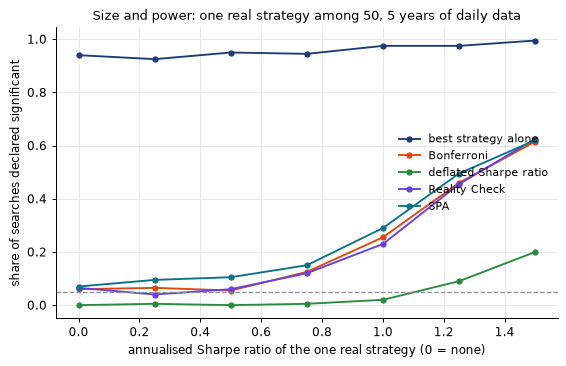

edge (annual Sharpe),best strategy alone,Bonferroni,deflated Sharpe ratio,Reality Check,SPA
0.00,94.0%,6.0%,0.0%,6.5%,7.0%
0.25,92.5%,6.5%,0.5%,4.0%,9.5%
0.50,95.0%,5.5%,0.0%,6.0%,10.5%
0.75,94.5%,12.5%,0.5%,12.0%,15.0%
1.00,97.5%,25.5%,2.0%,23.0%,29.0%
1.25,97.5%,46.0%,9.0%,45.5%,49.5%
1.50,99.5%,61.5%,20.0%,62.5%,62.0%


In [24]:
rng = np.random.default_rng(7)
edges_p, n_markets = [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5], 200
methods = [
    "best strategy alone",
    "Bonferroni",
    "deflated Sharpe ratio",
    "Reality Check",
    "SPA",
]
rates = {m: [] for m in methods}
for e in edges_p:
    hits = dict.fromkeys(methods, 0)
    for _ in range(n_markets):
        X = rng.standard_t(5, (T5, 50)) / math.sqrt(5 / 3) * 0.01
        X[:, 0] += e / ANN * 0.01
        s = sharpe(X)
        k = int(np.argmax(s))
        psr = psr_of(X[:, k])
        hits["best strategy alone"] += psr > 0.95
        hits["Bonferroni"] += psr > 1 - 0.05 / 50
        hits["deflated Sharpe ratio"] += (
            deflated_sharpe_ratio(X[:, k], 50, trial_sharpes=s).dsr > 0.95
        )
        hits["Reality Check"] += white_reality_check(X, 500, 10, seed=0).p_value < 0.05
        hits["SPA"] += hansen_spa(X, 500, 10, seed=0).p_value < 0.05
    for m in methods:
        rates[m].append(hits[m] / n_markets)
fig, ax = plt.subplots(figsize=(7.2, 4.2))
for m in methods:
    ax.plot(edges_p, rates[m], "o-", ms=4, label=m)
ax.axhline(0.05, color=GREY, ls="--", lw=1)
ax.set(
    xlabel="annualised Sharpe ratio of the one real strategy (0 = none)",
    ylabel="share of searches declared significant",
    title="Size and power: one real strategy among 50, 5 years of daily data",
)
ax.legend(loc="center right")
plt.show()
show_table(
    pd.DataFrame(rates, index=[f"{e:.2f}" for e in edges_p]),
    "edge (annual Sharpe)",
    "{:.1%}",
)

Ignoring the search is not a small error: with 50 independent strategies and no edge anywhere, the best one passes a 5% test in more than 90% of searches, as $1 - 0.95^{50} \approx 0.92$ predicts. Bonferroni, the Reality Check and SPA all hold the false-positive rate near 5% (between 6% and 7% here, within simulation error of 1.5 percentage points) and have similar power. With independent strategies this is expected, because the bootstrap's main advantage, its use of the correlation between strategies, has nothing to work with. The deflated Sharpe ratio almost never produces a false positive, but it is much less powerful: it detects a Sharpe ratio of 1.5 in about one search in five, against more than three in five for the bootstrap tests. The reason is the one given in Section 4: the DSR compares the winner with the *expected* best of $N$ trials and then asks for 1.65 standard errors more, which is a higher bar than "better than the 95th percentile of the best of $N$".

Even with the right correction, a strategy with a true Sharpe ratio of 1.0 is found in only about a quarter of five-year searches over 50 candidates. Short samples and wide searches make good strategies hard to tell apart from lucky ones, and no statistic can fix that; only more data or fewer, better-motivated trials can.

## 7. How often each check gets it right

The four checks are collected in one function, `overfitting_report`, which runs them on a matrix of returns with one column per trial: the deflated Sharpe ratio of the best column, PBO, the Reality Check and SPA.

In [25]:
def bootstrap_p(p, reps):
    """A bootstrap p-value of 0 only means 'below 1/reps'."""
    return f"< {1 / reps:.4f}".rstrip("0") if p == 0 else f"{p:.3f}"


@dataclass(frozen=True)
class OverfittingReport:
    best: int  # column with the highest Sharpe ratio
    periods_per_year: float
    n_periods: int
    deflated: DeflatedSharpe
    pbo: PBOResult
    reality_check: RealityCheck
    spa: SPA
    variance_supplied: bool

    @property
    def sharpe_annual(self):
        return self.deflated.sharpe * math.sqrt(self.periods_per_year)

    @property
    def threshold_annual(self):
        return self.deflated.threshold * math.sqrt(self.periods_per_year)

    def __str__(self):
        rows = [
            (
                "Best Sharpe (annualised)",
                f"{self.sharpe_annual:.2f}",
                f"best of {self.deflated.n_trials} strategies, {self.n_periods:,} periods",
            ),
            (
                "Expected best Sharpe from luck",
                f"{self.threshold_annual:.2f}",
                f"from {self.deflated.n_trials} trials with no skill"
                + (" (variance supplied)" if self.variance_supplied else ""),
            ),
            (
                "Deflated Sharpe ratio",
                f"{self.deflated.dsr:.3f}",
                "P(true Sharpe beats that luck threshold)",
            ),
            (
                "Probability of backtest overfitting",
                f"{self.pbo.pbo:.3f}",
                f"in-sample winner below median out of sample ({self.pbo.n_splits:,} splits)",
            ),
            (
                "White's Reality Check p-value",
                bootstrap_p(self.reality_check.p_value, self.reality_check.reps),
                "H0: no strategy beats the benchmark",
            ),
            (
                "Hansen's SPA p-value",
                bootstrap_p(self.spa.p_value, self.spa.reps),
                f"bounds {bootstrap_p(self.spa.p_lower, self.spa.reps)} – {bootstrap_p(self.spa.p_upper, self.spa.reps)}",
            ),
        ]
        w0, w1 = max(len(r[0]) for r in rows), max(len(r[1]) for r in rows)
        return "\n".join(f"{a:<{w0}}  {b:>{w1}}  {c}" for a, b, c in rows)


def overfitting_report(
    R,
    periods_per_year=252,
    n_trials=None,
    n_blocks=16,
    reps=2000,
    mean_block=10.0,
    seed=0,
    sharpe_variance=None,
):
    """All four checks for the best column of a T x N matrix of excess returns. `n_trials`
    defaults to N; pass the real number of configurations tried if it was larger."""
    R = np.asarray(R, dtype=float)
    srs = R.mean(0) / R.std(0, ddof=1)
    best = int(np.argmax(srs))
    return OverfittingReport(
        best=best,
        periods_per_year=periods_per_year,
        n_periods=len(R),
        deflated=deflated_sharpe_ratio(
            R[:, best], n_trials or R.shape[1], srs, sharpe_variance
        ),
        pbo=probability_of_backtest_overfitting(R, n_blocks),
        reality_check=white_reality_check(R, reps, mean_block, seed),
        spa=hansen_spa(R, reps, mean_block, seed),
        variance_supplied=sharpe_variance is not None,
    )

Sections 5 and 6 used stylised strategies. This section returns to the crossover search of Section 1, where the 110 rules are strongly correlated with each other, and repeats it on 100 random-walk markets and 100 trending markets (the trend of Section 5.2). For each market the full report is run: deflated Sharpe ratio, PBO, Reality Check and SPA.

In [26]:
def summarise(trend, n_markets=100):
    rows = []
    for seed in range(n_markets):
        R, _ = crossover_grid(market(trend=trend, seed=seed))
        rep = overfitting_report(R, periods_per_year=PPY, reps=500, seed=0)
        rows.append(
            {
                "best Sharpe": rep.sharpe_annual,
                "best alone significant": psr_of(R[:, rep.best]) > 0.95,
                "DSR > 0.95": rep.deflated.dsr > 0.95,
                "Reality Check p < 0.05": rep.reality_check.p_value < 0.05,
                "SPA p < 0.05": rep.spa.p_value < 0.05,
                "PBO": rep.pbo.pbo,
            }
        )
    return pd.DataFrame(rows)


calib = {"No edge": summarise(0.0), "Real trend": summarise(0.0015)}
calibration = pd.DataFrame(
    {
        label: {
            "median best Sharpe (annualised)": df["best Sharpe"].median(),
            "best rule alone significant (PSR > 0.95)": df[
                "best alone significant"
            ].mean(),
            "deflated Sharpe ratio > 0.95": df["DSR > 0.95"].mean(),
            "Reality Check p < 0.05": df["Reality Check p < 0.05"].mean(),
            "SPA p < 0.05": df["SPA p < 0.05"].mean(),
            "median PBO": df["PBO"].median(),
        }
        for label, df in calib.items()
    }
)
show_table(calibration, "", "{:.3f}")

,No edge,Real trend
median best Sharpe (annualised),0.446,1.983
best rule alone significant (PSR > 0.95),0.340,1.000
deflated Sharpe ratio > 0.95,0.020,0.960
Reality Check p < 0.05,0.050,0.980
SPA p < 0.05,0.070,0.980
median PBO,0.506,0.443


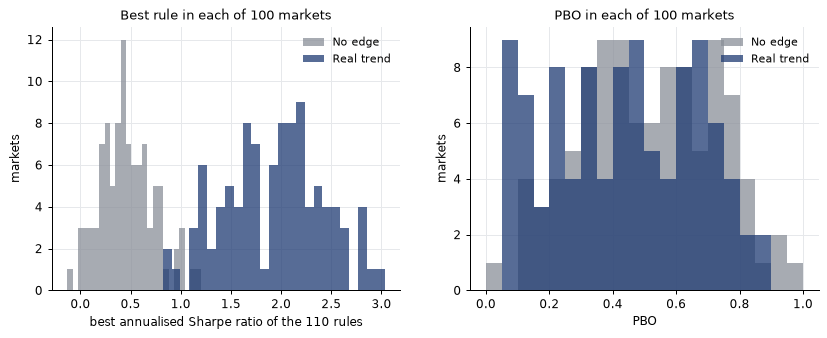

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for label, color in [("No edge", GREY), ("Real trend", NAVY)]:
    axes[0].hist(
        calib[label]["best Sharpe"], bins=25, alpha=0.75, color=color, label=label
    )
    axes[1].hist(
        calib[label]["PBO"], bins=20, range=(0, 1), alpha=0.75, color=color, label=label
    )
axes[0].set(
    xlabel="best annualised Sharpe ratio of the 110 rules",
    ylabel="markets",
    title="Best rule in each of 100 markets",
)
axes[1].set(xlabel="PBO", ylabel="markets", title="PBO in each of 100 markets")
axes[0].legend()
axes[1].legend()
plt.show()

On the random-walk markets the best of 110 crossover rules looks significant on its own in about a third of searches, as in Section 1. That is fewer than the 94% of Section 6.4 because these rules are highly correlated and behave like a much smaller number of independent tests, but still far above 5%. The corrected tests bring false positives back to roughly the nominal level (2% for the deflated Sharpe ratio, 5–7% for the bootstrap tests) while still detecting the real trend in almost every market. PBO is again the odd one out: its median is about 0.5 on noise and about 0.45 on the trending markets, because all 110 rules benefit from the same trend and choosing the in-sample winner among them is close to a coin toss, as in Section 5.3.

## 8. A research program on real data

Simulations show that the tools behave as intended when the answer is known. The real question is what they say about an ordinary research program on real markets. This section runs one: five well-known systematic strategies, each with the small parameter grid a researcher would try, 44 variants in all. Every variant is a market-neutral book, so the question for each one is simply whether it earns a positive return net of costs, and the question for the program is whether its best result is better than luck.

### 8.1 Data and costs

All data is free and is downloaded on the first run into `data/`, which is not part of the repository.

* **US equity industries.** Daily value-weighted returns of the 49 industry portfolios of Fama and French (1997), with the market factor and the one-month T-bill rate, from Kenneth French's data library. All 49 industries have data from July 1969. Industry portfolios avoid the survivorship bias of a stock universe built from today's index members, because CRSP includes firms that later delisted. The results use the release built from the September 2026 CRSP file; French revises past data from time to time, so later releases can move the numbers slightly.
* **Multi-asset ETFs.** Thirteen exchange-traded funds covering US, international and emerging equities, Treasuries, credit, inflation-linked bonds, gold, commodities and three currencies, from Yahoo Finance. The list was fixed once, as the largest established fund in each asset class with history from 2007, and was not varied. All thirteen still trade, so the list cannot contain a fund that closed; for flagship funds of this size the survivorship effect is likely small, but it is not zero. Prices are adjusted for splits and distributions, so returns include dividends and coupons, and are already net of each fund's expense ratio. The youngest fund, the dollar index ETF, starts in March 2007.

Every figure in this section is stated either **gross** or **net**, defined as follows.

| Item | Treatment |
|---|---|
| Benchmark | All returns are in excess of the one-month T-bill. Long positions are financed at the T-bill rate and short-sale proceeds earn it, so a book that stays flat earns exactly zero. |
| Trading costs | Commission, half the bid–ask spread and market impact, combined into one charge per unit of one-way turnover: 10 basis points for the industry portfolios (trading their large-cap constituents) and 3 basis points for the ETFs. |
| Financing and borrow | 25 basis points a year on gross notional: the spread over the T-bill rate on borrowed money for long positions and the stock-borrow fee on short positions. |
| Market hedge | Index futures, charged 1 basis point per unit of notional traded. Futures carry the T-bill financing in their price, so they add no financing cost of their own. |
| Risk management | Every change in exposure made to hold the volatility target (Section 8.3) is charged as trading, at the same rates. |
| Not included | Management and performance fees, taxes, and the higher trading costs of the 1970s and 1980s. Between rebalances, weights are held at their targets rather than left to drift with prices; the small trades this implies are not charged. |
| **Gross** | Excess return before trading costs, the financing spread and hedge costs. |
| **Net** | Excess return after all of the above. Every Sharpe ratio, test and chart below is net unless it says otherwise. |

Each book is built as follows. Target weights are set at the close of a rebalance day using data up to that close and held from the next trading day. The book's market exposure is hedged daily: its beta is the sum of each position's weight times that asset's beta against the market, estimated over the previous 252 days, and the hedge is set using yesterday's estimates. The size of the whole book is then managed to a volatility target, described in Section 8.3.

In [28]:
DATA = Path("data")
END = "2026-09-30"  # last day of the published results (Kenneth French's September 2026 release)
FRENCH_FTP = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"


def french_table(name, title):
    """One table of a Kenneth French data-library CSV, as decimal returns."""
    DATA.mkdir(exist_ok=True)
    path = DATA / f"{name}.zip"
    if not path.exists():
        urlretrieve(FRENCH_FTP + path.name, path)
    with zipfile.ZipFile(path) as z:
        text = z.read(z.namelist()[0]).decode("latin-1").replace("\r\n", "\n")
    block = next(b for b in text.split("\n\n") if title in b).strip()
    if not block.startswith(","):  # drop the title line above the header row
        block = block.split("\n", 1)[1]
    df = pd.read_csv(io.StringIO(block), index_col=0)
    df.index = pd.to_datetime(df.index.astype(str).str.strip(), format="%Y%m%d")
    df.columns = df.columns.str.strip()
    df = df.apply(pd.to_numeric, errors="coerce")
    return df.where(df > -99) / 100  # missing values are coded -99.99


def etf_closes(tickers):
    """Daily closes adjusted for splits and distributions, from Yahoo Finance."""
    DATA.mkdir(exist_ok=True)
    cols = {}
    for t in tickers:
        path = DATA / f"{t}.csv"
        if not path.exists():
            import yfinance as yf

            raw = yf.Ticker(t).history(period="max", auto_adjust=True)
            pd.DataFrame(
                {
                    "date": raw.index.strftime("%Y-%m-%d"),
                    "close": raw["Close"].to_numpy(),
                }
            ).to_csv(path, index=False)
        cols[t] = pd.read_csv(path, parse_dates=["date"]).set_index("date")["close"]
    return pd.DataFrame(cols).sort_index()


ff = french_table("F-F_Research_Data_Factors_daily_CSV", "Mkt-RF").loc[:END]
industries = french_table(
    "49_Industry_Portfolios_daily_CSV", "Average Value Weighted Returns -- Daily"
)
industries = industries.loc["1969-07-01":END].fillna(
    0.0
)  # one missing day: Softw, 1971-03-11
rf, mkt = ff["RF"], ff["Mkt-RF"]
X_ind = industries.sub(rf.loc[industries.index], axis=0)

ETFS = {
    "SPY": "US equities",
    "IWM": "US small caps",
    "EFA": "developed ex-US equities",
    "EEM": "emerging-market equities",
    "IEF": "7–10y Treasuries",
    "TLT": "20y+ Treasuries",
    "LQD": "investment-grade credit",
    "TIP": "inflation-linked Treasuries",
    "GLD": "gold",
    "DBC": "commodity futures",
    "UUP": "US dollar index",
    "FXE": "euro",
    "FXY": "yen",
}
etf = etf_closes(list(ETFS)).loc[
    "2007-03-01":END
]  # UUP, the youngest fund, starts here
r_etf = etf.pct_change().iloc[1:]
r_etf = r_etf.loc[r_etf.index.intersection(ff.index)]
X_etf = r_etf.sub(rf.loc[r_etf.index], axis=0)
if X_etf.isna().any().any():
    raise ValueError("missing ETF returns in the common sample")

print(
    f"industries: {X_ind.shape[1]} portfolios, {X_ind.index[0].date()} to {X_ind.index[-1].date()}"
)
print(
    f"ETFs: {X_etf.shape[1]} funds, {X_etf.index[0].date()} to {X_etf.index[-1].date()}"
)

industries: 49 portfolios, 1969-07-01 to 2026-09-30
ETFs: 13 funds, 2007-03-02 to 2026-09-30


### 8.2 The strategies

| Family | Universe | Rule | Grid | Variants |
|---|---|---|---|---|
| Time-series momentum (Moskowitz, Ooi and Pedersen, 2012) | 13 ETFs | Long each asset whose excess return over the past $L$ months is positive, short it otherwise; monthly | $L \in \{1, 3, 6, 9, 12\}$; equal or inverse-volatility weights | 10 |
| Industry momentum (Moskowitz and Grinblatt, 1999) | 49 industries | Rank on the return over $L$ months, skipping the most recent $s$; long the top $k$, short the bottom $k$, equal weights; monthly | $L \in \{3, 6, 12\}$, $s \in \{0, 1\}$, $k \in \{5, 10\}$ | 12 |
| Betting against beta (Frazzini and Pedersen, 2014) | 49 industries | Long low-beta, short high-beta industries, each leg levered or de-levered to a beta of one, so the book is beta-neutral by construction; monthly | beta window 1 or 3 years; raw betas or shrunk towards 1 ($0.6\hat\beta + 0.4$); rank weights or terciles | 8 |
| Short-term reversal (Lehmann, 1990) | 49 industries | Long the $k$ industries with the lowest return over the past $L$ days, short the $k$ highest | $L \in \{5, 21\}$ days; rebalanced weekly or monthly; $k \in \{5, 10\}$ | 8 |
| Low volatility (Blitz and van Vliet, 2007; Baker, Bradley and Wurgler, 2011) | 49 industries | Long the $k$ least volatile industries over the past $L$ days, short the $k$ most volatile; monthly | $L \in \{21, 63, 252\}$; $k \in \{5, 10\}$ | 6 |

The grids are deliberately small and conventional. None of these strategies is new, so this is a test of known ideas on one particular data set rather than a hunt for something original, which is the more common situation in practice. Betting-against-beta books are built to be beta-neutral using their own beta estimates and are not hedged again; every other book carries the futures hedge described above.

### 8.3 Risk management: a 15% volatility target

A rule such as "long the top five industries, short the bottom five" fixes the *direction* of each position but not the size of the book, and the volatility of a fixed-size book varies a great deal over time: it roughly doubles in a crisis. Every book here is therefore run the way systematic portfolios usually are, at a fixed annual volatility target. The book's volatility is forecast every day and its exposure is scaled to bring the forecast to the target. The target is a long-run level, not a daily guarantee: realised volatility moves around it, because forecasts are imperfect and exposure is adjusted only when it is materially off.

| Setting | Choice |
|---|---|
| Annual volatility target | 15% |
| Volatility forecast | GARCH(1,1), one day ahead, made every day from returns up to the previous close |
| Estimation | Re-estimated every January on all of the book's returns to date (expanding window), then applied unchanged for that year |
| Start of each book | No position for the first 63 days, which initialise the forecast; then RiskMetrics EWMA (decay 0.94; J.P. Morgan/Reuters, 1996) until the first January after two years of returns, when GARCH takes over |
| Position adjustment | Daily, with a no-trade band: exposure changes only when it is more than 10% away from the target exposure, or on a rebalance day |
| Exposure limit | Gross notional (longs plus shorts, excluding the futures hedge) at most 5 times capital |
| Costs | Every change in exposure is charged at the trading-cost rates above; financing is charged on the levered notional |

**How.** Let $u_t$ be the daily return of one unit of a book, before costs. GARCH(1,1) (Bollerslev, 1986) forecasts its variance from yesterday's squared return and yesterday's forecast,

$$\hat\sigma^2_{t} = \omega + \alpha\, u_{t-1}^2 + \beta\, \hat\sigma^2_{t-1}, \qquad \omega = \bar s^2 (1 - \alpha - \beta),$$

where $\bar s^2$ is the sample variance of the returns used for estimation, so the forecasts revert to the book's long-run variance at a rate set by $\alpha + \beta$. The book then holds

$$k_t = \min\!\left(\frac{0.15}{\sqrt{252}\,\hat\sigma_t},\ \frac{5}{G_t}\right)$$

units, where $G_t$ is the gross notional of one unit; $k_t$ is changed only if the new value is more than 10% away from the current one. Both $\hat\sigma_t$ and $G_t$ are known at the close of day $t-1$, so there is no look-ahead.

**Why GARCH.** Volatility clusters and mean-reverts. A rolling window of the last 63 days captures neither well: it weights a shock no more than any other day, reacts slowly, and then drops the shock abruptly 63 days later. EWMA reacts at once, but its forecast depends only on recent returns, with no pull towards a long-run level. GARCH(1,1) adds that pull with two estimated parameters, and EWMA is the special case $\omega = 0$, $\alpha + \beta = 1$, which is why it is a natural stand-in until GARCH can be estimated. With persistence near 0.99, as here, the pull is slow and one-day GARCH forecasts are close to EWMA's; the gain from GARCH is real but modest.

**Keeping the overlay from becoming a search.** The overlay is a second place where a researcher can search, so its specification is fixed and reported in full: GARCH(1,1), Gaussian quasi-maximum likelihood, variance targeting (so only $\alpha$ and $\beta$ are estimated), the 15% target, the 10% band and the leverage cap, identical for all 44 books. For the record, an earlier draft of this note managed the books to 10% volatility with a 63-day rolling estimate; it was replaced because it did not charge the trades it generated, and the specification above was fixed before any results with it were computed. Every estimate is out of sample: the parameters used in a year come only from earlier years. Section 8.5 reruns the whole program with EWMA and with the 63-day window in place of GARCH; the conclusions do not change, and GARCH is not the most flattering of the three.

**What it changes.** Scaling by a forecast that varies over time is not neutral: it changes each book's Sharpe ratio. It tends to raise it when expected returns do not rise in proportion to risk in turbulent periods (Moreira and Muir, 2017, who scale by inverse variance), and for momentum in particular because its crashes come in high-volatility periods (Barroso and Santa-Clara, 2015); Cederburg, O'Doherty, Wang and Yan (2020) find the gains less reliable out of sample. The tables therefore also report each book's net Sharpe ratio at constant exposure, so the contribution of the overlay is visible. Equal volatility across books has a second benefit: no single book can dominate the Reality Check through its variance alone (Section 6.3).

In [29]:
VOL_TARGET = 0.15  # annualised volatility each book is managed to
BAND = (
    0.10  # no-trade band: exposure is changed only when it is more than 10% off target
)
MAX_GROSS = 5.0  # cap on gross notional (longs plus shorts, excluding the futures hedge) per unit of capital


def rebalance_days(index, freq):
    """Last trading day of each month ("M") or week ("W")."""
    period = index.to_period("M" if freq == "M" else "W-FRI")
    return index.to_series().groupby(period).tail(1).index


def trailing_return(X, days, lookback, skip=0):
    """Excess return over `lookback` rebalance periods ending `skip` periods before each day."""
    growth = np.log1p(X).cumsum().loc[days]
    return np.expm1(growth.shift(skip) - growth.shift(skip + lookback))


def long_short(score, k, long_high=True):
    """+1/k on the k highest scores and -1/k on the k lowest (reversed if long_high=False)."""
    rank = score.rank(axis=1, ascending=not long_high, method="first")
    n = score.notna().sum(axis=1).to_numpy()[:, None]
    w = (rank <= k).astype(float) / k - (rank > n - k).astype(float) / k
    return w.where(score.notna().all(axis=1))


def garch_variance(r, omega, alpha, beta, v0):
    """Forecasts v[t] = omega + alpha r[t-1]^2 + beta v[t-1], starting from v[0] = v0; the
    output has one more element than r. A linear filter, so it runs at C speed."""
    x = omega + alpha * np.asarray(r) ** 2
    return np.r_[v0, lfilter([1.0], [1.0, -beta], x, zi=[beta * v0])[0]]


def fit_garch(r):
    """GARCH(1,1) by Gaussian quasi-maximum likelihood with variance targeting: omega is tied
    to the sample variance, so only alpha and beta are estimated."""
    r = np.asarray(r, dtype=float)
    s2 = r.var()

    def neg_loglik(theta):
        persistence, share = theta  # alpha + beta, and alpha's share of it
        alpha, beta = persistence * share, persistence * (1 - share)
        v = garch_variance(r[:-1], s2 * (1 - persistence), alpha, beta, s2)
        return 0.5 * np.sum(np.log(v) + r**2 / v)

    fit = minimize(
        neg_loglik,
        x0=[0.97, 0.08],
        bounds=[(0.5, 0.999), (0.005, 0.5)],
        method="L-BFGS-B",
    )
    persistence, share = fit.x
    return s2 * (1 - persistence), persistence * share, persistence * (1 - share)


def variance_forecasts(r, dates, warmup=63, min_fit=504, model="garch"):
    """One-day-ahead variance forecast for every day, using returns up to the day before.
    RiskMetrics EWMA (lambda = 0.94, the GARCH(1,1) with omega = 0, alpha = 0.06,
    beta = 0.94) until two years of returns exist; from then on GARCH(1,1), re-estimated
    every January on all returns to date and applied unchanged for that calendar year."""
    r = np.asarray(r, dtype=float)
    if model == "rolling 63 days":  # used only for the robustness check in Section 8.5
        return pd.Series(r**2).rolling(warmup).mean().shift(1).to_numpy(), {}
    years = np.asarray(dates.year)
    out, fits = np.full(len(r), np.nan), {}
    v, params, t = r[:warmup].var(), (0.0, 0.06, 0.94), warmup
    while t < len(r):
        end = (
            t + int(np.argmax(years[t:] != years[t]))
            if (years[t:] != years[t]).any()
            else len(r)
        )
        if t >= min_fit and model == "garch":
            params = fit_garch(r[:t])
            fits[dates[t].year] = params
        path = garch_variance(r[t - 1 : end - 1], *params, v)
        out[t:end], v, t = path[1:], path[-1], end
    return out, fits


def run_book(
    targets,
    X,
    betas,
    trade_cost,
    hedge=True,
    delay=0,
    financing=0.0025,
    hedge_cost=0.0001,
    vol_target=VOL_TARGET,
    band=BAND,
    max_gross=MAX_GROSS,
    forecast="garch",
):
    """Daily returns of a book whose weights are set on rebalance days, managed to an annual
    volatility target with GARCH forecasts. `delay` postpones every trade by that many extra
    days (a check for look-ahead)."""
    w = (
        targets.reindex(X.index).ffill().shift(1 + delay)
    )  # decided at the close, held from the next day
    live = w.notna().all(axis=1)
    w = w.loc[live]
    Xl, m = X.loc[w.index], mkt.loc[w.index]
    h = (
        (w * betas.shift(1).loc[w.index]).sum(axis=1)
        if hedge
        else pd.Series(0.0, index=w.index)
    )
    unit = (w * Xl).sum(axis=1) - h * m  # one unit of the book, before costs
    gross_notional = w.abs().sum(axis=1)
    rebalance = w.diff().abs().sum(axis=1).fillna(1.0).to_numpy() > 0

    var_hat, fits = variance_forecasts(unit.to_numpy(), unit.index, model=forecast)
    sigma_hat = np.sqrt(var_hat * PPY)
    wanted = np.minimum(vol_target / sigma_hat, max_gross / gross_notional.to_numpy())
    scale = np.full(len(unit), np.nan)
    s = 0.0
    for t in range(
        len(unit)
    ):  # trade only on rebalance days or when exposure is off target by more than the band
        if np.isfinite(wanted[t]) and (
            s == 0.0 or rebalance[t] or abs(wanted[t] / s - 1) > band
        ):
            s = wanted[t]
        scale[t] = s if np.isfinite(wanted[t]) else np.nan
    scale = pd.Series(scale, index=unit.index)

    def costs(k):  # trading, financing and hedge costs of holding k units of the book
        pos, hedge_pos = w.mul(k.fillna(0.0), axis=0), h * k.fillna(0.0)
        turnover = (
            pos.diff().abs().sum(axis=1).fillna(pos.abs().sum(axis=1))
        )  # day one: entering
        return (
            turnover,
            trade_cost * turnover,
            financing / PPY * pos.abs().sum(axis=1),
            hedge_cost * hedge_pos.diff().abs().fillna(hedge_pos.abs()),
        )

    turnover, trading, funding, hedging = costs(scale)
    _, const_trading, const_funding, const_hedging = costs(
        pd.Series(1.0, index=unit.index)
    )
    out = pd.DataFrame(
        {
            "gross": scale * unit,
            "net": scale * unit - trading - funding - hedging,
            "turnover": turnover,
            "trading": trading,
            "funding": funding,
            "hedging": hedging,
            "scale": scale,
            "forecast vol": sigma_hat,
            "gross leverage": scale * gross_notional,
            "net, constant exposure": unit
            - const_trading
            - const_funding
            - const_hedging,
        }
    )
    out.attrs["garch"] = fits
    return out.dropna()


def market_betas(X, window=252):
    m = mkt.loc[X.index]
    return X.rolling(window).cov(m).div(m.rolling(window).var(), axis=0)


books, family, specs = {}, {}, {}


def add(fam, name, *spec, **options):
    books[name] = run_book(*spec, **options)
    family[name], specs[name] = fam, (spec, options)


# time-series momentum on the ETFs
beta_etf = market_betas(X_etf)
me_etf = rebalance_days(X_etf.index, "M")
vol_etf = X_etf.rolling(63).std().loc[me_etf] * ANN
for L in (1, 3, 6, 9, 12):
    direction = np.sign(trailing_return(X_etf, me_etf, L))
    for weights in ("equal", "inverse-vol"):
        w = (
            direction / len(ETFS)
            if weights == "equal"
            else direction * (0.10 / vol_etf) / len(ETFS)
        )
        add(
            "Time-series momentum", f"TSMOM {L}m, {weights}", w, X_etf, beta_etf, 0.0003
        )

# the industry books
beta_ind = market_betas(X_ind)
me_ind, we_ind = rebalance_days(X_ind.index, "M"), rebalance_days(X_ind.index, "W")
for L in (3, 6, 12):
    for s in (0, 1):
        score = trailing_return(X_ind, me_ind, L, s)
        for k in (5, 10):
            add(
                "Industry momentum",
                f"MOM {L}-{s}, {k}/{k}",
                long_short(score, k),
                X_ind,
                beta_ind,
                0.0010,
            )

log_ind, log_mkt = np.log1p(X_ind), np.log1p(mkt.loc[X_ind.index])
for years in (1, 3):
    n_days = 252 * years
    beta_ts = log_ind.rolling(n_days).corr(log_mkt) * log_ind.rolling(n_days).std().div(
        log_mkt.rolling(n_days).std(), axis=0
    )
    for shrunk in (False, True):
        b = (0.6 * beta_ts + 0.4 if shrunk else beta_ts).loc[me_ind]
        for scheme in ("rank", "tercile"):
            if (
                scheme == "rank"
            ):  # Frazzini-Pedersen rank weights, each leg summing to one
                dev = b.rank(axis=1).sub(b.rank(axis=1).mean(axis=1), axis=0)
                w_low = (
                    (-dev).clip(lower=0).div((-dev).clip(lower=0).sum(axis=1), axis=0)
                )
                w_high = dev.clip(lower=0).div(dev.clip(lower=0).sum(axis=1), axis=0)
            else:
                pct = b.rank(axis=1, pct=True)
                w_low = (
                    (pct <= 1 / 3).astype(float).div((pct <= 1 / 3).sum(axis=1), axis=0)
                )
                w_high = (
                    (pct > 2 / 3).astype(float).div((pct > 2 / 3).sum(axis=1), axis=0)
                )
            w = w_low.div((w_low * b).sum(axis=1), axis=0) - w_high.div(
                (w_high * b).sum(axis=1), axis=0
            )
            label = f"BAB {years}y{' shrunk' if shrunk else ''}, {scheme}"
            add(
                "Betting against beta",
                label,
                w.where(b.notna().all(axis=1)),
                X_ind,
                beta_ind,
                0.0010,
                hedge=False,
            )

growth_ind = np.log1p(X_ind).cumsum()
for L in (5, 21):
    past = np.expm1(growth_ind - growth_ind.shift(L))
    for freq, days in (("weekly", we_ind), ("monthly", me_ind)):
        for k in (5, 10):
            w = long_short(past.loc[days], k, long_high=False)
            add(
                "Short-term reversal",
                f"REV {L}d {freq}, {k}/{k}",
                w,
                X_ind,
                beta_ind,
                0.0010,
            )

for L in (21, 63, 252):
    vol = X_ind.rolling(L).std().loc[me_ind]
    for k in (5, 10):
        add(
            "Low volatility",
            f"LOWVOL {L}d, {k}/{k}",
            long_short(vol, k, long_high=False),
            X_ind,
            beta_ind,
            0.0010,
        )

FAMILIES = list(dict.fromkeys(family.values()))
net = pd.DataFrame({n: b["net"] for n, b in books.items()})
gross = pd.DataFrame({n: b["gross"] for n, b in books.items()})
print(
    f"{net.shape[1]} books:",
    ", ".join(f"{f} {sum(v == f for v in family.values())}" for f in FAMILIES),
)

44 books: Time-series momentum 10, Industry momentum 12, Betting against beta 8, Short-term reversal 8, Low volatility 6


Three checks on the overlay, over each book's full history: whether realised volatility lands near the target, how often the leverage cap binds, and how the GARCH forecasts compare out of sample with the two simpler forecasts discussed above. Forecasts are scored with the QLIKE loss, $\log \hat\sigma^2_t + u_t^2/\hat\sigma^2_t$, which is minimised by the true conditional variance and is robust to the noise in using $u_t^2$ as a proxy for it (Patton, 2011). The comparison starts once a book has two years of history; GARCH takes over at the following January, so the first months of the comparison still use EWMA, which if anything works against GARCH.

In [30]:
def overlay_check(b):
    u = (b["gross"] / b["scale"]).to_numpy()  # one unit of the book
    garch = (b["forecast vol"].to_numpy() / ANN) ** 2
    ewma = np.r_[
        u[:63].var(),
        lfilter([0.06], [1.0, -0.94], u[:-1] ** 2, zi=[0.94 * u[:63].var()])[0],
    ]
    rolling = pd.Series(u**2).rolling(63).mean().shift(1).to_numpy()
    keep = slice(504, None)
    loss = {
        name: np.nanmean(np.log(v[keep]) + u[keep] ** 2 / v[keep])
        for name, v in [
            ("GARCH(1,1)", garch),
            ("EWMA, decay 0.94", ewma),
            ("rolling 63 days", rolling),
        ]
    }
    return loss, b["net"].std() * ANN, (b["gross leverage"] > MAX_GROSS - 1e-9).mean()


checks = {n: overlay_check(b) for n, b in books.items()}
losses = pd.DataFrame({n: c[0] for n, c in checks.items()}).T
realised = pd.Series({n: c[1] for n, c in checks.items()})
capped = pd.Series({n: c[2] for n, c in checks.items()})
print(
    f"realised volatility of the 44 managed books: {realised.min():.1%} to {realised.max():.1%} (median {realised.median():.1%})"
)
print(
    f"leverage cap binding: median {capped.median():.1%} of days; above 10% of days for {(capped > 0.10).sum()} books, "
    f"all of them {', '.join(sorted({family[n] for n in capped[capped > 0.10].index}))}"
)
show_table(
    pd.DataFrame(
        {
            "mean QLIKE loss relative to GARCH": losses.sub(
                losses["GARCH(1,1)"], axis=0
            ).mean(),
            "books for which it is the most accurate": losses.idxmin(axis=1)
            .value_counts()
            .reindex(losses.columns)
            .fillna(0),
        }
    ),
    "forecast",
    {
        "mean QLIKE loss relative to GARCH": "{:+.4f}",
        "books for which it is the most accurate": "{:.0f}",
    },
)

realised volatility of the 44 managed books: 14.0% to 15.7% (median 15.1%)
leverage cap binding: median 4.4% of days; above 10% of days for 15 books, all of them Betting against beta, Time-series momentum


forecast,mean QLIKE loss relative to GARCH,books for which it is the most accurate
"GARCH(1,1)",+0.0000,44
"EWMA, decay 0.94",+0.0106,0
rolling 63 days,+0.0476,0


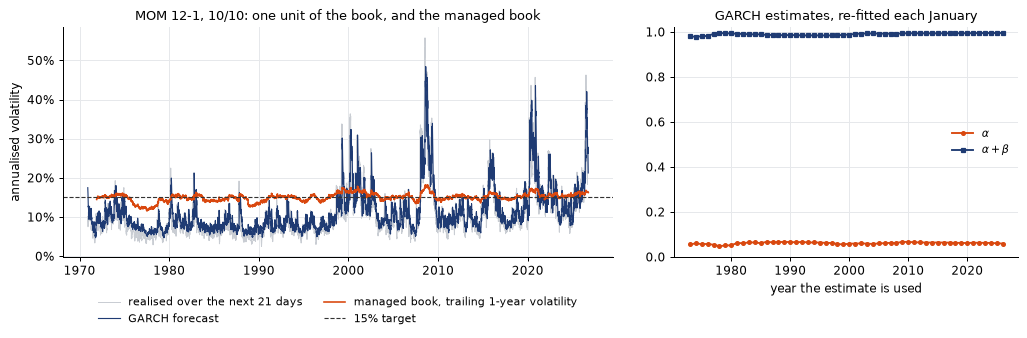

In [31]:
example = "MOM 12-1, 10/10"
b = books[example]
fits = pd.DataFrame(b.attrs["garch"], index=["omega", "alpha", "beta"]).T
fig, axes = plt.subplots(
    1, 2, figsize=(11.5, 3.9), gridspec_kw={"width_ratios": [1.6, 1]}
)
unit = b["gross"] / b["scale"]
axes[0].plot(
    b.index,
    (unit.rolling(21).std() * ANN).shift(-21),
    color=LIGHT,
    lw=0.8,
    label="realised over the next 21 days",
)
axes[0].plot(b.index, b["forecast vol"], color=NAVY, lw=0.9, label="GARCH forecast")
axes[0].plot(
    b.index,
    b["net"].rolling(252).std() * ANN,
    color=ORANGE,
    lw=1.3,
    label="managed book, trailing 1-year volatility",
)
axes[0].axhline(VOL_TARGET, color="#333", ls="--", lw=0.9, label="15% target")
axes[0].set(
    ylabel="annualised volatility",
    title=f"{example}: one unit of the book, and the managed book",
)
axes[0].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
axes[1].plot(fits.index, fits["alpha"], "o-", ms=3, color=ORANGE, label=r"$\alpha$")
axes[1].plot(
    fits.index,
    fits["alpha"] + fits["beta"],
    "s-",
    ms=3,
    color=NAVY,
    label=r"$\alpha + \beta$",
)
axes[1].set(
    ylim=(0, 1.02),
    xlabel="year the estimate is used",
    title="GARCH estimates, re-fitted each January",
)
axes[1].legend(loc="center right")
fig.tight_layout()
plt.show()

The overlay does what it is meant to. Realised volatility of the 44 managed books ranges from 14.0% to 15.7% over their histories (median 15.1%). The time-series momentum books sit slightly below target because the leverage cap binds on about a fifth of days: inverse-volatility weights on low-volatility assets such as Treasuries need a lot of notional. The betting-against-beta books hit the cap on a similar share of days; for the other families it typically binds on fewer than 2% of days. Out of sample, GARCH has the lowest QLIKE loss for every one of the 44 books, ahead of EWMA and well ahead of the 63-day window. In the chart, one unit of the momentum book ranges from under 10% to about 50% volatility (in mid-2008), while the trailing one-year volatility of the managed book stays between about 12% and 18%. The estimates are stable from year to year ($\alpha$ between 0.05 and 0.07, $\alpha + \beta$ between 0.98 and 0.996), as an expanding window makes them; across all books and years the persistence bound of 0.999 binds in 7 of 2,012 fits.

### 8.4 The whole program, 2008–2026

The ETFs limit the common sample to the period in which all 44 books are trading: from the end of June 2008 to September 2026, about 18 years. The table summarises each family by its best variant (highest net Sharpe ratio); the chart shows every variant, gross and net. The bootstrap tests use a mean block length of 21 days, about the holding period of the monthly books; the results for 10 and 63 days are reported further down.

In [32]:
def book_stats(names, start, end=END):
    """Net and gross statistics of each book over [start, end]."""
    rows = {}
    for n in names:
        b = books[n].loc[start:end]
        const = b["net, constant exposure"]
        rows[n] = {
            "net Sharpe": b["net"].mean() / b["net"].std() * ANN,
            "gross Sharpe": b["gross"].mean() / b["gross"].std() * ANN,
            "net Sharpe (constant)": const.mean() / const.std() * ANN,
            "t (net)": b["net"].mean() / b["net"].std() * math.sqrt(len(b)),
            "volatility (%)": 100 * b["net"].std() * ANN,
            "turnover (× a year)": b["turnover"].mean() * PPY,
            "costs (% a year)": 100
            * (b["trading"] + b["funding"] + b["hedging"]).mean()
            * PPY,
            # trading cost per unit of turnover at which the mean net return reaches zero,
            # with the financing spread and the hedge cost unchanged
            "break-even (bp)": 1e4
            * (b["gross"] - b["funding"] - b["hedging"]).mean()
            / b["turnover"].mean(),
            "beta": np.polyfit(mkt.loc[b.index], b["net"], 1)[0],
        }
    return pd.DataFrame(rows).T


BOOK_FORMAT = {
    "net Sharpe": "{:.2f}",
    "gross Sharpe": "{:.2f}",
    "net Sharpe (constant)": "{:.2f}",
    "t (net)": "{:.1f}",
    "volatility (%)": "{:.1f}",
    "turnover (× a year)": "{:.1f}",
    "costs (% a year)": "{:.2f}",
    "break-even (bp)": "{:.0f}",
    "beta": lambda v: f"{round(v, 2) + 0:+.2f}",
}
SHORT = {
    "Time-series momentum": "TS momentum",
    "Industry momentum": "Ind. momentum",
    "Betting against beta": "BAB",
    "Short-term reversal": "Reversal",
    "Low volatility": "Low vol",
}


def best_of_each_family(table):
    """The variant with the highest net Sharpe ratio in each family, labelled by family."""
    fam = pd.Series({n: family[n] for n in table.index})
    picks = table["net Sharpe"].groupby(fam).idxmax()
    out = table.loc[[picks[f] for f in FAMILIES if f in picks]]
    out.insert(0, "best variant", out.index)
    out.index = [SHORT[family[n]] for n in out.index]
    return out


BLOCK = 21  # mean block length for the bootstrap tests, in days
P = net.dropna().loc[:END]
stats_all = book_stats(P.columns, P.index[0])
print(
    f"{P.shape[1]} books, {P.index[0].date()} to {P.index[-1].date()}, {len(P):,} days ({len(P) / PPY:.1f} years)"
)
print(
    f"volatility management raises the net Sharpe ratio of "
    f"{(stats_all['net Sharpe'] > stats_all['net Sharpe (constant)']).sum()} of {len(stats_all)} books"
)
show_table(best_of_each_family(stats_all), "family", BOOK_FORMAT)

44 books, 2008-06-30 to 2026-09-30, 4,592 days (18.2 years)
volatility management raises the net Sharpe ratio of 26 of 44 books


family,best variant,net Sharpe,gross Sharpe,net Sharpe (constant),t (net),volatility (%),turnover (× a year),costs (% a year),break-even (bp),beta
TS momentum,"TSMOM 9m, inverse-vol",0.45,0.60,0.42,1.9,14.1,31.2,2.05,24,-0.03
Ind. momentum,"MOM 12-1, 5/5",0.33,0.48,0.17,1.4,15.4,17.7,2.23,39,-0.01
BAB,"BAB 3y, rank",0.30,0.45,0.18,1.3,15.2,15.5,2.32,39,+0.01
Reversal,"REV 5d monthly, 10/10",-0.41,0.10,-0.23,-1.7,15.6,71.4,7.97,1,+0.00
Low vol,"LOWVOL 252d, 5/5",0.49,0.55,0.26,2.1,15.3,5.6,0.98,143,+0.03


In [33]:
def constant_exposure(frame):
    """The same books at constant exposure, each scaled by one number to 15% volatility over
    the sample (a constant scale changes no Sharpe ratio; it puts the Reality Check on an
    equal footing)."""
    c = pd.DataFrame(
        {n: books[n]["net, constant exposure"] for n in frame.columns}
    ).loc[frame.index]
    return c / (c.std() * ANN) * VOL_TARGET


def analyse(frame):
    const = constant_exposure(frame)
    return {
        "managed": overfitting_report(frame.to_numpy(), PPY, mean_block=BLOCK),
        "managed, variance 1/T": overfitting_report(
            frame.to_numpy(), PPY, mean_block=BLOCK, sharpe_variance=1 / len(frame)
        ),
        "constant": overfitting_report(const.to_numpy(), PPY, mean_block=BLOCK),
        "constant, variance 1/T": overfitting_report(
            const.to_numpy(), PPY, mean_block=BLOCK, sharpe_variance=1 / len(frame)
        ),
    }


reports_all = analyse(P)
print(f"best book: {P.columns[reports_all['managed'].best]}\n")
print(reports_all["managed"])

best book: LOWVOL 252d, 5/5

Best Sharpe (annualised)              0.49  best of 44 strategies, 4,592 periods
Expected best Sharpe from luck        0.95  from 44 trials with no skill
Deflated Sharpe ratio                0.025  P(true Sharpe beats that luck threshold)
Probability of backtest overfitting  0.444  in-sample winner below median out of sample (12,870 splits)
White's Reality Check p-value        0.292  H0: no strategy beats the benchmark
Hansen's SPA p-value                 0.333  bounds 0.281 – 0.417


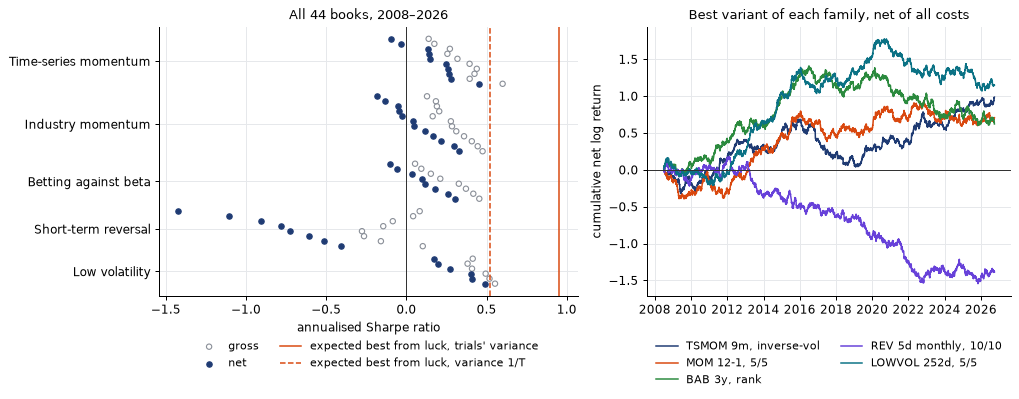

In [34]:
def sharpe_dot_plot(ax, table, names, thresholds, title):
    order = [
        n
        for f in FAMILIES
        for n in sorted(
            (m for m in names if family[m] == f),
            key=lambda m: table.loc[m, "net Sharpe"],
        )
    ]
    y, ticks, labels, pos = [], [], [], 0.0
    for f in FAMILIES:
        members = [n for n in order if family[n] == f]
        if not members:
            continue
        ys = pos + np.arange(len(members))
        ticks.append(ys.mean())
        labels.append(f)
        y.extend(ys)
        pos += len(members) + 1.5
    y = np.array(y)
    ax.scatter(
        table.loc[order, "gross Sharpe"],
        y,
        s=18,
        facecolors="none",
        edgecolors=GREY,
        lw=0.9,
        label="gross",
    )
    ax.scatter(
        table.loc[order, "net Sharpe"], y, s=18, color=NAVY, label="net", zorder=3
    )
    for value, label, style in thresholds:
        ax.axvline(value, color=ORANGE, ls=style, lw=1.2, label=label)
    ax.axvline(0, color="#333", lw=0.8)
    ax.set_yticks(ticks, labels)
    ax.invert_yaxis()
    ax.set(xlabel="annualised Sharpe ratio", title=title)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)


rep = reports_all["managed"]
fig, axes = plt.subplots(
    1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1.15, 1]}
)
sharpe_dot_plot(
    axes[0],
    stats_all,
    P.columns,
    [
        (rep.threshold_annual, "expected best from luck, trials' variance", "-"),
        (
            reports_all["managed, variance 1/T"].threshold_annual,
            "expected best from luck, variance 1/T",
            "--",
        ),
    ],
    f"All {P.shape[1]} books, {P.index[0].year}–{P.index[-1].year}",
)
for f, color in zip(FAMILIES, [NAVY, ORANGE, GREEN, PURPLE, TEAL], strict=True):
    n = best_of_each_family(stats_all).loc[SHORT[f], "best variant"]
    axes[1].plot(P.index, np.log1p(P[n]).cumsum(), color=color, lw=1.2, label=n)
axes[1].axhline(0, color="#333", lw=0.8)
axes[1].set(
    ylabel="cumulative net log return",
    title="Best variant of each family, net of all costs",
)
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
fig.tight_layout()
plt.show()

Costs separate the families clearly. Managing exposure every day adds trading on top of each rule's own rebalancing: the time-series and industry momentum books turn over 18 to 75 times their capital a year and pay 1.7% to 4.9% a year in costs, which takes about 0.15 off the best Sharpe ratio of each family, and betting against beta loses as much. The best low-volatility book trades least, pays about 1% a year and loses 0.06. Short-term reversal turns over 48 to 228 times a year; every variant loses money net of costs, and the best breaks even at a trading cost of about 1 basis point, far below what real execution costs. The hedge does its job: the realised beta of every hedged book is within ±0.05 of zero. The betting-against-beta books, which rely on their own beta estimates, range from −0.24 (shrunk betas, which understate the difference between the legs) to +0.05.

Volatility management raises 26 of the 44 net Sharpe ratios: the best low-volatility book earns 0.49 managed against 0.26 at constant exposure, and the best industry momentum book 0.33 against 0.17. It lowers every reversal book, whose extra trading it makes more expensive, and leaves time-series momentum slightly worse on average. The overlay is identical for all books and part of each strategy's definition rather than an extra trial; the constant-exposure figures show how much of each result it accounts for. (For the tests, the constant-exposure books are scaled by a single number, chosen after the fact, to 15% volatility over each sample. That changes no Sharpe ratio, DSR, PBO or SPA $p$-value; it only puts the Reality Check, which compares raw means, on an equal footing.)

The best book of the program is the 252-day low-volatility book, with a net Sharpe ratio of 0.49 and a $t$-statistic of 2.1 (1.9 after allowing for autocorrelation). Taken on its own that is borderline at the 5% level. It passes none of the tests that account for the search: the Reality Check and SPA give $p$-values of 0.29 and 0.33, PBO is 0.44 (choosing the in-sample winner is close to a coin toss), and the deflated Sharpe ratio is 0.03. Its $t$-statistic is also well short of the hurdle of 3 that Harvey, Liu and Zhu (2016) propose for new findings, to allow for the number of strategies the profession as a whole has tried. The table further down shows that the conclusion is the same at constant exposure and with blocks of 10 or 63 days.

### 8.5 Fifty-four years of industry data

The ETFs cover only the last two decades, but the industry data go back to 1969. Without the ten time-series momentum books, the remaining 34 books can be run from January 1973, after three years of warm-up, to September 2026: almost 54 years, three times the sample above. Two caveats come with the extra data. Trading costs are kept at today's levels, which flatters the early decades, when commissions and spreads were several times higher. And the early decades are not out of sample for these ideas: industry momentum was documented on data up to 1995 (Moskowitz and Grinblatt, 1999), betting against beta and low volatility on similar periods.

In [35]:
industry_books = [n for n in net.columns if not n.startswith("TSMOM")]
Q = net[industry_books].loc["1973-01-02":END]
if Q.isna().any().any():
    raise ValueError("an industry book is not live for the whole sample")
stats_long = book_stats(Q.columns, Q.index[0])
reports_long = analyse(Q)
print(
    f"{Q.shape[1]} books, {Q.index[0].date()} to {Q.index[-1].date()}, {len(Q):,} days ({len(Q) / PPY:.1f} years)"
)
print(f"best book: {Q.columns[reports_long['managed'].best]}\n")
print(reports_long["managed"])
show_table(best_of_each_family(stats_long), "family", BOOK_FORMAT)

34 books, 1973-01-02 to 2026-09-30, 13,550 days (53.8 years)
best book: MOM 12-0, 10/10

Best Sharpe (annualised)              0.66  best of 34 strategies, 13,550 periods
Expected best Sharpe from luck        1.41  from 34 trials with no skill
Deflated Sharpe ratio                0.000  P(true Sharpe beats that luck threshold)
Probability of backtest overfitting  0.021  in-sample winner below median out of sample (12,870 splits)
White's Reality Check p-value        0.001  H0: no strategy beats the benchmark
Hansen's SPA p-value                 0.002  bounds 0.001 – 0.002


family,best variant,net Sharpe,gross Sharpe,net Sharpe (constant),t (net),volatility (%),turnover (× a year),costs (% a year),break-even (bp),beta
Ind. momentum,"MOM 12-0, 10/10",0.66,0.89,0.45,4.9,15.2,26.6,3.47,48,+0.03
BAB,"BAB 3y, rank",0.39,0.57,0.27,2.9,14.8,16.7,2.60,45,+0.06
Reversal,"REV 5d monthly, 5/5",-0.59,-0.18,-0.40,-4.3,15.1,55.3,6.17,-6,-0.01
Low vol,"LOWVOL 252d, 5/5",0.11,0.19,0.04,0.8,15.1,6.6,1.20,36,+0.05


With three times the data the conclusion changes. The best book is industry momentum with a 12-month formation period, no skip and ten industries on each side (the version that skips the latest month is close behind at 0.64). It earns a net Sharpe ratio of 0.66 with $t = 4.9$, or 3.9 after allowing for autocorrelation, above the hurdle of 3. Both bootstrap tests reject the hypothesis that no book has a positive mean return (Reality Check $p = 0.001$, SPA $p = 0.002$), and PBO is 0.02: in almost every split, the in-sample winner also beats the median book out of sample. At constant exposure the result is weaker. The bootstrap tests and PBO still reject (best book 0.45, Reality Check $p = 0.011$, SPA $p = 0.015$, PBO 0.008), but the dependence-adjusted $t$-statistic falls to 3.0, at the hurdle, and the DSR with variance $1/T$ to 0.87, below 0.95. Part of the momentum result is therefore the overlay's contribution.

These tests are about the best book. Betting against beta, the second family, earns 0.39 with $t = 2.9$ (0.27 at constant exposure), so on its own it does not clear the hurdle of 3; establishing it separately would need a stepwise procedure such as that of Romano and Wolf (2005), which controls the error rate for every strategy declared significant, not just the best. Low volatility, the best family since 2008, earns 0.11 over the full period. Short-term reversal loses money even before costs, consistent with Moskowitz and Grinblatt's (1999) finding that industries show momentum rather than reversal at short horizons. The table below puts the verdicts on both samples side by side.

In [36]:
def adjusted_t(x):
    """t-statistic of the mean with the stationary-bootstrap long-run variance (BLOCK days)."""
    return (
        x.mean()
        * math.sqrt(len(x))
        / math.sqrt(long_run_variance(x[:, None], BLOCK)[0])
    )


def verdict(frame, reports):
    rep, rep_null = reports["managed"], reports["managed, variance 1/T"]
    const, const_null = reports["constant"], reports["constant, variance 1/T"]
    best = frame.columns[rep.best]
    x = frame[best].to_numpy()
    no_rev = [n for n in frame.columns if family[n] != "Short-term reversal"]
    sr = (frame.mean() / frame.std()).to_numpy()
    sr_no_rev = (frame[no_rev].mean() / frame[no_rev].std()).to_numpy()
    eigenvalues = np.linalg.eigvalsh(frame.corr().to_numpy())
    n_eff = eigenvalues.sum() ** 2 / (eigenvalues**2).sum()  # participation ratio
    dsr_eff = deflated_sharpe_ratio(
        x, n_trials=max(2, round(n_eff)), sharpe_variance=1 / len(frame)
    )
    other = {
        b: (
            white_reality_check(frame.to_numpy(), 1000, b, 0).p_value,
            hansen_spa(frame.to_numpy(), 1000, b, 0).p_value,
        )
        for b in (10, 63)
    }

    def p(value, reps=2000):
        return bootstrap_p(value, reps)

    return {
        "best book": best,
        "best net Sharpe": f"{rep.sharpe_annual:.2f}",
        "t-stat of the best": f"{x.mean() / x.std(ddof=1) * math.sqrt(len(x)):.1f}",
        f"t-stat of the best, dependence-adjusted ({BLOCK}-day blocks)": f"{adjusted_t(x):.1f}",
        "dispersion of trial Sharpes / noise": f"{np.var(sr, ddof=1) * len(frame):.1f}",
        "the same, without the reversal books": f"{np.var(sr_no_rev, ddof=1) * len(frame):.1f}",
        "luck threshold, trials' variance": f"{rep.threshold_annual:.2f}",
        "DSR, trials' variance": f"{rep.deflated.dsr:.3f}",
        "luck threshold, variance 1/T": f"{rep_null.threshold_annual:.2f}",
        "DSR, variance 1/T": f"{rep_null.deflated.dsr:.3f}",
        "effective number of independent trials": f"{n_eff:.1f}",
        "luck threshold, effective trials and variance 1/T": f"{dsr_eff.threshold * ANN:.2f}",
        "DSR, effective trials and variance 1/T": f"{dsr_eff.dsr:.3f}",
        "PBO": f"{rep.pbo.pbo:.3f}",
        "PBO without the reversal books": f"{probability_of_backtest_overfitting(frame[no_rev].to_numpy()).pbo:.3f}",
        f"Reality Check p ({BLOCK}-day blocks)": p(rep.reality_check.p_value),
        f"SPA p ({BLOCK}-day blocks)": p(rep.spa.p_value),
        "Reality Check p, 10 / 63-day blocks": f"{p(other[10][0], 1000)} / {p(other[63][0], 1000)}",
        "SPA p, 10 / 63-day blocks": f"{p(other[10][1], 1000)} / {p(other[63][1], 1000)}",
        "constant exposure: best net Sharpe": f"{const.sharpe_annual:.2f}",
        "constant exposure: t-stat of the best, dependence-adjusted": f"{adjusted_t(constant_exposure(frame).iloc[:, const.best].to_numpy()):.1f}",
        "constant exposure: DSR, trials' variance / 1/T": f"{const.deflated.dsr:.3f} / {const_null.deflated.dsr:.3f}",
        "constant exposure: PBO": f"{const.pbo.pbo:.3f}",
        "constant exposure: Reality Check p / SPA p": f"{p(const.reality_check.p_value)} / {p(const.spa.p_value)}",
    }


verdicts = pd.DataFrame(
    {
        f"{P.index[0].year}–{P.index[-1].year}, {P.shape[1]} books": verdict(
            P, reports_all
        ),
        f"{Q.index[0].year}–{Q.index[-1].year}, {Q.shape[1]} books": verdict(
            Q, reports_long
        ),
    }
)
show_table(verdicts, "")

,"2008–2026, 44 books","1973–2026, 34 books"
best book,"LOWVOL 252d, 5/5","MOM 12-0, 10/10"
best net Sharpe,0.49,0.66
t-stat of the best,2.1,4.9
"t-stat of the best, dependence-adjusted (21-day blocks)",1.9,3.9
dispersion of trial Sharpes / noise,3.3,23.7
"the same, without the reversal books",0.5,2.5
"luck threshold, trials' variance",0.95,1.41
"DSR, trials' variance",0.025,0.000
"luck threshold, variance 1/T",0.52,0.29
"DSR, variance 1/T",0.444,0.997


The deflated Sharpe ratio is the exception. With the trials' own variance it is 0.000: it rates a momentum book with a dependence-adjusted $t$-statistic of 3.9 as no better than luck. Its luck threshold, 1.41, is more than twice the best Sharpe ratio in the search, because the 34 Sharpe ratios are 24 times as dispersed as sampling noise would make them. Most of that dispersion is real: the momentum books earn up to 0.66 a year and the reversal books lose between 0.6 and 1.9; without the reversal books the ratio falls to 2.5. The variance in $SR_0$ is meant to measure how far luck alone spreads the trials (Section 3.2). Computed from a search that mixes good and bad strategies, it also contains the real differences between them, and that part does not shrink as the sample grows, while the noise does. With the variance set to its value under the null hypothesis, $1/T$, the threshold is 0.29 and the DSR is 0.997, in line with the other tests. López de Prado and Lewis (2019) address the same problem by clustering the trials and estimating the variance across clusters.

Comparing the trials' variance with $1/T$ is a useful diagnostic, not a rule. A ratio well above one says the trials differ by more than noise, and the DSR built from their variance will be too strict. A ratio near or below one does not prove the opposite, because correlation between trials pulls the dispersion down (Section 3.2) while genuine differences push it up: without the reversal books the 2008–2026 ratio is 0.5. Nor is $1/T$ a guaranteed bound, since it treats the trials as independent and their returns as serially uncorrelated, and neither holds here. In the 2008–2026 program the choice moves the DSR from 0.03 to 0.44; neither clears 0.95, so the conclusion there does not depend on it.

Correlation also means that 44 trials are far from 44 independent tests: variants of one idea move together, and low volatility overlaps with betting against beta. A simple estimate of the effective number of trials is the participation ratio of the eigenvalues $\lambda_i$ of the trials' return correlation matrix, $N_{\text{eff}} = (\sum_i \lambda_i)^2 / \sum_i \lambda_i^2$, which equals $N$ for uncorrelated trials and 1 for identical ones. It is about 7 for the 44 books of 2008–2026 and 6 for the 34 industry books. With $N_{\text{eff}}$ and the null variance $1/T$, the most lenient version of the test in the table, the luck threshold for 2008–2026 falls to 0.32 and the DSR of the best book rises to 0.76, still short of 0.95, so the conclusion for the recent sample does not depend on how the trials are counted either. The participation ratio is one estimate among several; López de Prado and Lewis (2019) cluster the trials instead.

Two other rows deserve a note. PBO is helped by the reversal books, which are reliably bad and so make the in-sample winner look good against the median: without them PBO is 0.56 rather than 0.44 over 2008–2026, and 0.07 rather than 0.02 over 1973–2026. And the bootstrap $p$-values move little with the block length, so neither conclusion depends on it.

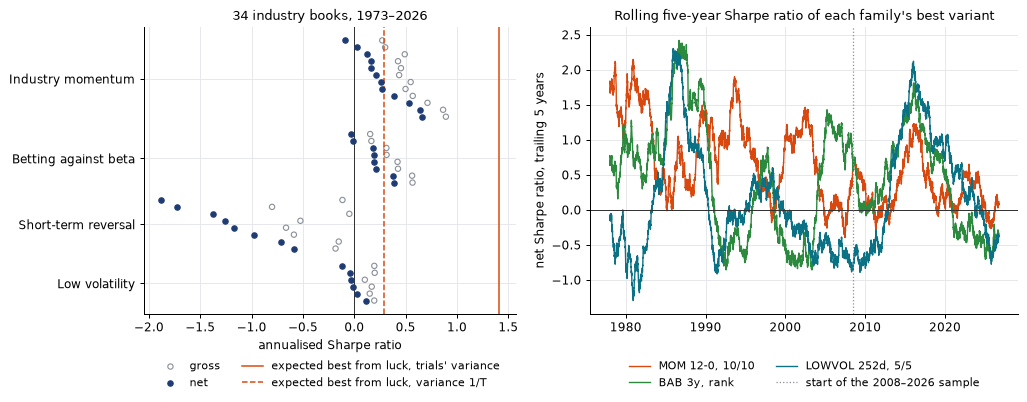

In [37]:
fig, axes = plt.subplots(
    1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1, 1.15]}
)
sharpe_dot_plot(
    axes[0],
    stats_long,
    Q.columns,
    [
        (
            reports_long["managed"].threshold_annual,
            "expected best from luck, trials' variance",
            "-",
        ),
        (
            reports_long["managed, variance 1/T"].threshold_annual,
            "expected best from luck, variance 1/T",
            "--",
        ),
    ],
    f"{Q.shape[1]} industry books, {Q.index[0].year}–{Q.index[-1].year}",
)
window = 5 * PPY
for f, color in [
    ("Industry momentum", ORANGE),
    ("Betting against beta", GREEN),
    ("Low volatility", TEAL),
]:
    n = best_of_each_family(stats_long).loc[SHORT[f], "best variant"]
    rolling = Q[n].rolling(window).mean() / Q[n].rolling(window).std() * ANN
    axes[1].plot(rolling.index, rolling, color=color, lw=1.1, label=n)
axes[1].axhline(0, color="#333", lw=0.8)
axes[1].axvline(
    P.index[0], color=GREY, ls=":", lw=1, label="start of the 2008–2026 sample"
)
axes[1].set(
    ylabel="net Sharpe ratio, trailing 5 years",
    title="Rolling five-year Sharpe ratio of each family's best variant",
)
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
fig.tight_layout()
plt.show()

The rolling Sharpe ratios show why the two samples disagree. The momentum book earned a Sharpe ratio of 1.8 in 1973–79, 0.8 in the 1980s and 1.0 in the 1990s, then 0.07 in the 2000s (including the momentum crash of 2009; Daniel and Moskowitz, 2016), 0.4 in the 2010s and 0.2 since 2020: 0.92 before July 2008 and 0.16 after (0.78 and 0.04 at constant exposure). Betting against beta and low volatility alternate between strong and negative decades. The longer sample therefore does not simply add power to the same experiment. Most of the momentum result comes from the decades in which the strategy was discovered and published, and the period after 2008, the closest thing to an out-of-sample test here, shows nothing significant. Whether the weak recent record reflects arbitrage after publication (McLean and Pontiff, 2016) or an unlucky stretch is beyond what these tests can tell.

In [38]:
def overlay_summary(frames):
    """Best book, its net Sharpe ratio and the bootstrap tests, for each version of the program."""
    out = {}
    for overlay, books_net in frames.items():
        row = {}
        for label, idx, cols in [
            ("2008–2026", P.index, P.columns),
            ("1973–2026", Q.index, Q.columns),
        ]:
            frame = books_net.loc[idx, cols]
            if overlay == "constant exposure":
                frame = frame / (frame.std() * ANN) * VOL_TARGET
            rep_ = overfitting_report(
                frame.to_numpy(), PPY, reps=1000, mean_block=BLOCK
            )
            row[f"{label}: best book"] = frame.columns[rep_.best]
            row[f"{label}: net Sharpe"] = f"{rep_.sharpe_annual:.2f}"
            row[f"{label}: t, dependence-adjusted"] = (
                f"{adjusted_t(frame.iloc[:, rep_.best].to_numpy()):.1f}"
            )
            row[f"{label}: Reality Check p / SPA p"] = (
                f"{bootstrap_p(rep_.reality_check.p_value, 1000)} / "
                f"{bootstrap_p(rep_.spa.p_value, 1000)}"
            )
        out[overlay] = row
    return pd.DataFrame(out)


versions = {"GARCH(1,1), as published": net}
for label, model in [
    ("EWMA, decay 0.94", "ewma"),
    ("rolling 63 days", "rolling 63 days"),
]:
    versions[label] = pd.DataFrame(
        {
            n: run_book(*spec, **(options | {"forecast": model}))["net"]
            for n, (spec, options) in specs.items()
        }
    )
versions["constant exposure"] = pd.DataFrame(
    {n: b["net, constant exposure"] for n, b in books.items()}
)
show_table(overlay_summary(versions), "")

,"GARCH(1,1), as published","EWMA, decay 0.94",rolling 63 days,constant exposure
2008–2026: best book,"LOWVOL 252d, 5/5","LOWVOL 252d, 5/5","LOWVOL 252d, 5/5","TSMOM 9m, inverse-vol"
2008–2026: net Sharpe,0.49,0.48,0.54,0.42
"2008–2026: t, dependence-adjusted",1.9,1.9,2.1,1.7
2008–2026: Reality Check p / SPA p,0.283 / 0.329,0.304 / 0.350,0.181 / 0.226,0.406 / 0.439
1973–2026: best book,"MOM 12-0, 10/10","MOM 12-0, 10/10","MOM 12-1, 10/10","MOM 12-0, 10/10"
1973–2026: net Sharpe,0.66,0.68,0.70,0.45
"1973–2026: t, dependence-adjusted",3.9,4.0,4.1,3.0
1973–2026: Reality Check p / SPA p,0.001 / 0.001,0.001 / 0.001,0.001 / 0.001,0.009 / 0.012


The table above reruns the whole program with the GARCH forecast replaced by EWMA and by the 63-day rolling window, and at constant exposure (bootstrap tests with 1,000 draws). The conclusions do not depend on the overlay: nothing passes over 2008–2026 in any version, and an industry momentum book is the best and passes the bootstrap tests over 1973–2026 in every version. GARCH gives neither the highest Sharpe ratios nor the smallest $p$-values of the three forecasts; the 63-day window, the least accurate forecast by QLIKE, flatters the results most. At constant exposure the momentum book's dependence-adjusted $t$-statistic is 3.0.

In [39]:
delayed = {}
for label, frame, table in [("2008–2026", P, stats_all), ("1973–2026", Q, stats_long)]:
    for n in best_of_each_family(table)["best variant"]:
        spec, options = specs[n]
        late = run_book(*spec, **options, delay=1)["net"].loc[frame.index[0] : END]
        on_time = books[n]["net"].loc[frame.index[0] : END]
        delayed[f"{n} ({label})"] = {
            "net Sharpe": on_time.mean() / on_time.std() * ANN,
            "entering one day late": late.mean() / late.std() * ANN,
        }
delayed = pd.DataFrame(delayed).T
delayed["change"] = delayed["entering one day late"] - delayed["net Sharpe"]
show_table(
    delayed,
    "best variant (sample)",
    {
        "net Sharpe": "{:.2f}",
        "entering one day late": "{:.2f}",
        "change": lambda v: f"{round(v, 2) + 0:+.2f}",
    },
)

best variant (sample),net Sharpe,entering one day late,change
"TSMOM 9m, inverse-vol (2008–2026)",0.45,0.44,-0.02
"MOM 12-1, 5/5 (2008–2026)",0.33,0.29,-0.04
"BAB 3y, rank (2008–2026)",0.30,0.31,+0.00
"REV 5d monthly, 10/10 (2008–2026)",-0.41,-0.40,+0.01
"LOWVOL 252d, 5/5 (2008–2026)",0.49,0.51,+0.02
"MOM 12-0, 10/10 (1973–2026)",0.66,0.66,+0.00
"BAB 3y, rank (1973–2026)",0.39,0.39,+0.00
"REV 5d monthly, 5/5 (1973–2026)",-0.59,-0.56,+0.03
"LOWVOL 252d, 5/5 (1973–2026)",0.11,0.11,+0.00


The table above checks for the most common form of look-ahead: trading at the same close that produced the signal. Each family's best variant is rerun with every rebalance made one day later than the rule allows (the overlay and the hedge are unchanged). A backtest that depends on that close usually loses much of its performance under this change; one that does not changes little. No Sharpe ratio moves by more than 0.05. The check only catches look-ahead of up to a day; longer leaks, such as using data before its release date, need other checks.

### 8.6 What the case study shows

* Over the most recent 18 years, nothing in a program of 44 variants of well-known strategies survives the search, with or without volatility management, although the best book has a $t$-statistic of 2.1 and the best of each family looks respectable on its own.
* Over 54 years, the best industry momentum book passes the Reality Check, SPA and PBO. But those years include the decades in which industry momentum was discovered, and its record since 2008 is weak: the longer sample adds power and in-sample history at the same time.
* The tests agree, except for the deflated Sharpe ratio built from the trials' variance, which fails when the search mixes good and bad strategies. Comparing that variance with $1/T$ shows when this is happening.
* The volatility overlay raises most Sharpe ratios and is part of the strategy design, fixed rather than searched over. It does not change the conclusion for 2008–2026. Over 1973–2026 the bootstrap tests and PBO still reject at constant exposure, but the momentum result is then only at the $t$ = 3 hurdle and fails the DSR with variance $1/T$, so part of that result comes from the overlay. Replacing GARCH with EWMA or a 63-day window changes little.
* For fast strategies, costs matter more than the choice of test: short-term reversal is marginal before costs and negative after them in every variant.

## 9. Practical notes and limitations

**Count every trial, and decide before looking.** The deflated Sharpe ratio, the Reality Check and SPA all depend on the set of strategies considered. Configurations that were tried and dropped, earlier versions of the idea, and ideas tested by colleagues on the same data all belong in that set. The reliable way to know $N$ is to write the hypothesis, the benchmark and the parameter grid down before running anything and to keep a trial log from the first backtest. A final holdout period, used once at the very end, gives one test that no search has touched. The same applies to everything wrapped around a strategy: a volatility target, a stop-loss or a leverage rule that was tried and then kept or dropped is a trial too. These statistics correct for a search that was recorded; they cannot correct for one that was not.

**Use the tests together.** They answer different questions. The DSR and the bootstrap tests ask whether the best result is better than luck; PBO asks whether picking the in-sample winner is a sensible procedure. A search can pass one and fail the other, as the trending market in Section 7 shows. Fixed cut-offs such as "PBO below 0.2" are best avoided on their own: PBO stays near one half both when every trial shares the same real edge (Section 5.3) and when there is no detectable edge at all (Section 8.4).

**Check the variance behind the deflated Sharpe ratio.** When the trials' Sharpe ratios are much more dispersed than $1/T$, the search contains genuinely different strategies and the DSR built from their sample variance is too strict (Section 8.5). Reporting it with both variances costs one line.

**Report gross and net.** A multiple-testing correction applied to gross returns answers a question nobody trades. The cost assumptions should be stated item by item, and the break-even cost per unit of turnover compared with a realistic estimate of execution cost. Short-term reversal in Section 8 is the example: marginal gross, negative net in every variant, with a break-even cost of about 1 basis point.

**Dependence over time.** The Sharpe ratio standard errors in Sections 2 to 4 assume independent returns. Strategies with persistent positions have autocorrelated returns, for which the i.i.d. formulas understate uncertainty (Lo, 2002). The bootstrap tests handle this through the block length, which should be long enough to cover the autocorrelation of the returns being tested; Section 8 uses 21 days and shows that 10 or 63 days lead to the same conclusions. CSCV splits the history into blocks without regard to holding periods; where positions or labels overlap the boundary between a training and a test block, combinatorial purged cross-validation (López de Prado, 2018) removes the overlapping observations and adds an embargo after each test block. For the monthly strategies in Section 8 the overlap is at most a month at each boundary, small next to blocks of one to three and a half years.

**Non-stationarity.** Every method here treats the sample as draws from one distribution. Markets change, and a strategy that worked in the first half of a sample and stopped working in the second is a different problem from one that never worked. Industry momentum in Section 8.5 is an example: significant over 54 years, with a Sharpe ratio of 0.16 since 2008. Walk-forward analysis and a holdout period that is never used for selection address that, and complement the statistics in this notebook.

**Power is the binding constraint.** Section 6.4 showed that a genuine Sharpe ratio of 1.0 is found in only a quarter of five-year searches over 50 candidates, and Section 8 showed the same effect on real data. A negative result is often "not enough evidence" rather than "no edge". The way to more power is more data, a smaller and better-motivated set of trials, or both.

**What the tests do not catch.** Look-ahead bias, survivorship bias, unrealistic fills and costs, and errors in the data all inflate backtests in ways that multiple-testing corrections cannot detect. These statistics assume the backtests are computed correctly and only correct for having run many of them. Simple checks such as entering one day late (Section 8.5) guard against the most common of these errors.

## 10. References

* Bailey, D. H. and López de Prado, M. (2012). The Sharpe ratio efficient frontier. *Journal of Risk* 15(2), 3–44.
* Bailey, D. H. and López de Prado, M. (2014). The deflated Sharpe ratio: correcting for selection bias, backtest overfitting and non-normality. *Journal of Portfolio Management* 40(5), 94–107.
* Bailey, D. H., Borwein, J., López de Prado, M. and Zhu, Q. J. (2017). The probability of backtest overfitting. *Journal of Computational Finance* 20(4), 39–69.
* Baker, M., Bradley, B. and Wurgler, J. (2011). Benchmarks as limits to arbitrage: understanding the low-volatility anomaly. *Financial Analysts Journal* 67(1), 40–54.
* Barroso, P. and Santa-Clara, P. (2015). Momentum has its moments. *Journal of Financial Economics* 116(1), 111–120.
* Blitz, D. and van Vliet, P. (2007). The volatility effect. *Journal of Portfolio Management* 34(1), 102–113.
* Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics* 31(3), 307–327.
* Cederburg, S., O'Doherty, M. S., Wang, F. and Yan, X. (2020). On the performance of volatility-managed portfolios. *Journal of Financial Economics* 138(1), 95–117.
* Daniel, K. and Moskowitz, T. J. (2016). Momentum crashes. *Journal of Financial Economics* 122(2), 221–247.
* Fama, E. F. and French, K. R. (1997). Industry costs of equity. *Journal of Financial Economics* 43(2), 153–193.
* Frazzini, A. and Pedersen, L. H. (2014). Betting against beta. *Journal of Financial Economics* 111(1), 1–25.
* Hansen, P. R. (2005). A test for superior predictive ability. *Journal of Business & Economic Statistics* 23(4), 365–380.
* Harvey, C. R., Liu, Y. and Zhu, H. (2016). … and the cross-section of expected returns. *Review of Financial Studies* 29(1), 5–68.
* J.P. Morgan/Reuters (1996). *RiskMetrics — Technical Document*, 4th edition. New York: J.P. Morgan.
* Lehmann, B. N. (1990). Fads, martingales, and market efficiency. *Quarterly Journal of Economics* 105(1), 1–28.
* Lo, A. W. (2002). The statistics of Sharpe ratios. *Financial Analysts Journal* 58(4), 36–52.
* López de Prado, M. (2018). *Advances in Financial Machine Learning*. Wiley.
* López de Prado, M. and Lewis, M. J. (2019). Detection of false investment strategies using unsupervised learning methods. *Quantitative Finance* 19(9), 1555–1565.
* McLean, R. D. and Pontiff, J. (2016). Does academic research destroy stock return predictability? *Journal of Finance* 71(1), 5–32.
* Mertens, E. (2002). Comments on variance of the IID estimator in Lo (2002). Working paper.
* Moreira, A. and Muir, T. (2017). Volatility-managed portfolios. *Journal of Finance* 72(4), 1611–1644.
* Moskowitz, T. J. and Grinblatt, M. (1999). Do industries explain momentum? *Journal of Finance* 54(4), 1249–1290.
* Moskowitz, T. J., Ooi, Y. H. and Pedersen, L. H. (2012). Time series momentum. *Journal of Financial Economics* 104(2), 228–250.
* Patton, A. J. (2011). Volatility forecast comparison using imperfect volatility proxies. *Journal of Econometrics* 160(1), 246–256.
* Politis, D. N. and Romano, J. P. (1994). The stationary bootstrap. *Journal of the American Statistical Association* 89(428), 1303–1313.
* Romano, J. P. and Wolf, M. (2005). Stepwise multiple testing as formalized data snooping. *Econometrica* 73(4), 1237–1282.
* White, H. (2000). A reality check for data snooping. *Econometrica* 68(5), 1097–1126.

Data: Kenneth R. French, Data Library, Tuck School of Business at Dartmouth (49 industry portfolios and the Fama–French factors, daily); Yahoo Finance (ETF prices).

## Appendix A. Checking the implementation

Every estimator above is written for speed: PBO computes the Sharpe ratios of all 12,870 splits with one matrix product, the bootstrap tests store each resample as a vector of counts, and the long-run variance uses an FFT. Each shortcut is checked here against the slow and obvious calculation on a small example. The statistical behaviour of the estimators (coverage of the Sharpe ratio standard error, the expected maximum, the size of each test) is checked by the simulations in the main text.

In [40]:
rng = np.random.default_rng(1)
T_, N_, S_ = 320, 10, 8
R_ = rng.normal(0, 0.01, (T_, N_))
fast = probability_of_backtest_overfitting(R_, n_blocks=S_)
blocks_ = np.array_split(np.arange(T_), S_)
slow = []
for c in combinations(range(S_), S_ // 2):
    train_rows = np.concatenate([blocks_[k] for k in c])
    test_rows = np.concatenate([blocks_[k] for k in range(S_) if k not in c])
    winner = int(np.argmax(sharpe(R_[train_rows])))
    oos = sharpe(R_[test_rows])
    w = ((oos < oos[winner]).sum() + 1) / (N_ + 1)
    slow.append(math.log(w / (1 - w)))
print(
    f"PBO, {len(slow)} splits: largest difference in a logit {np.abs(fast.logits - slow).max():.1e}, "
    f"PBO {fast.pbo:.4f} against {np.mean(np.array(slow) <= 0):.4f} by brute force"
)

X_ = rng.normal(0, 1, (60, 2))
X_[:, 1] = np.convolve(X_[:, 0], [1, 0.6], "same")  # an autocorrelated column
p_ = 1 / 7
Xc_ = X_ - X_.mean(0)
by_hand = (Xc_**2).sum(0) / len(X_)
for i in range(1, len(X_)):
    kappa = (1 - i / len(X_)) * (1 - p_) ** i + (i / len(X_)) * (1 - p_) ** (
        len(X_) - i
    )
    by_hand = by_hand + 2 * kappa * (Xc_[i:] * Xc_[:-i]).sum(0) / len(X_)
print(
    f"long-run variance: largest relative difference from the sum written out "
    f"{np.abs(long_run_variance(X_, 7) / by_hand - 1).max():.1e}"
)

X_ = rng.normal(0, 0.01, (400, 6))
X_[:, 2] += 0.0006
reps_, block_, seed_ = 300, 10.0, 9
rc_, spa_ = (
    white_reality_check(X_, reps_, block_, seed_),
    hansen_spa(X_, reps_, block_, seed_),
)
draws = np.random.default_rng(seed_)  # the same random numbers, used the slow way
idx_ = np.concatenate(
    [
        stationary_bootstrap_indices(len(X_), block_, min(100, reps_ - s), draws)
        for s in range(0, reps_, 100)
    ]
)
d_, sq_ = X_.mean(0), math.sqrt(len(X_))
rc_slow = np.mean([sq_ * (X_[i].mean(0) - d_).max() >= sq_ * d_.max() for i in idx_])
om_ = np.sqrt(long_run_variance(X_, block_))
mu_ = np.where(sq_ * d_ / om_ <= -math.sqrt(2 * math.log(math.log(len(X_)))), d_, 0.0)
stat_ = max(0.0, (sq_ * d_ / om_).max())
spa_slow = np.mean(
    [max(0.0, (sq_ * (X_[i].mean(0) - d_ + mu_) / om_).max()) >= stat_ for i in idx_]
)
print(f"Reality Check p-value {rc_.p_value:.4f}, resampling row by row {rc_slow:.4f}")
print(f"SPA p-value {spa_.p_value:.4f}, resampling row by row {spa_slow:.4f}")

PBO, 70 splits: largest difference in a logit 0.0e+00, PBO 0.4429 against 0.4429 by brute force
long-run variance: largest relative difference from the sum written out 6.7e-16
Reality Check p-value 0.2600, resampling row by row 0.2600
SPA p-value 0.1567, resampling row by row 0.1567
